# Lung Cancer Bioactivity Prediction Using Molecular Descriptors and Machine Learning

**Type:** Cheminformatics / QSAR project  |  **Language:** Python (RDKit, scikit-learn, LightGBM, XGBoost, SHAP)  |  **Environment:** local Jupyter or Google Colab

 > **Scope note.** The configured BindingDB-style dataset is dominated by **EGFR** measurements, a molecular target relevant to subsets of lung cancer, especially non-small-cell lung cancer (NSCLC). This notebook reports measured EGFR-associated bioactivity; it does not predict tumor response, clinical benefit, or treatment suitability. Target names and assay context should be verified before making cancer-specific interpretations.

**Contents:** 1 Introduction · 2 Setup · 3 Load/explore · 4 Endpoint & cleaning · 5 pIC50 · 6 Dedup · 7 Descriptors · 8 Fingerprints · 9 Split · 10-12 Models · 13 Comparison · 14 CV · 15 Tuning · 16 Explainability · 17 Applicability domain · 18 Candidate screening · 19 GNN (optional) · 20 ChemBERTa (optional) · 21 Lung cancer relevance · 22 Results · 23 Limitations · 24 Export · 25 Conclusion

# 1. Project Introduction

### Lung cancer
Lung cancer includes biologically distinct diseases, principally non-small-cell lung cancer (NSCLC) and small-cell lung cancer. Some NSCLC tumors carry actionable alterations such as EGFR mutations, ALK rearrangements, or changes involving KRAS, BRAF, MET, RET, ERBB2, and NTRK. Targeted medicines can benefit selected patients whose tumors have the corresponding alteration; treatment selection depends on tumor testing and clinical evidence. This notebook models biochemical activity measurements, not tumor response or patient outcomes.

### Why computational drug discovery?
Experimental screening is slow and expensive. Computational methods can **prioritise** compounds for synthesis and assay, explore large chemical spaces, and learn structure–activity relationships (SAR) from existing data. They *complement* experiments; they do not replace them.

### What is molecular bioactivity prediction?
Given a molecule's structure, a supervised model predicts a measured activity against a specific biological target (here, IC50). When the model is trained on compounds tested against **one defined protein target**, it is a *target-specific QSAR* (Quantitative Structure–Activity Relationship) model. The supplied data are EGFR-dominated, which is relevant to a subset of lung cancers, but the data alone do not establish tumor indication or clinical efficacy.

### Why pIC50 / pKi?
IC50 and Ki span many orders of magnitude (pM to mM) and are roughly log-normally distributed. The negative log transform
$$\text{pIC50} = -\log_{10}(\text{IC50 [mol/L]}) = 9 - \log_{10}(\text{IC50 [nM]})$$
yields a more symmetric, approximately homoscedastic target where higher = more potent (IC50 = 10 nM → pIC50 = 8). The same applies to Ki → pKi.

### Molecular representations
* **Physicochemical descriptors** (MW, logP, TPSA, H-bond donors/acceptors, …) are interpretable and relate to molecular properties.
* **Morgan (circular, ECFP-like) fingerprints** encode local substructures as bits and capture SAR patterns that global descriptors miss.
* Combining both gives complementary information.

### Models
* **Random Forest** – robust bagged-tree baseline; little tuning needed; good with high-dimensional sparse bits.
* **LightGBM / XGBoost** – gradient-boosted trees; typically strong on tabular QSAR data, handle non-linear interactions, and provide gain-based importance and SHAP explanations.
* **Optional advanced approaches** – Graph Neural Networks (learn directly on atom/bond graphs) and ChemBERTa (a transformer pre-trained on SMILES). Both are shown in optional sections.

### What this project does — and does not — claim
| Concept | Meaning | Covered here? |
|---|---|---|
| Molecular bioactivity prediction | Predict a measured potency value from structure | Yes |
| EGFR-target QSAR | Predict activity against the measured EGFR construct | Yes |
| Lung-tumor response | Predict response in a patient or tumor model | No |
| Clinical treatment outcome | Benefit, safety, and survival in patients | No |

**A high predicted pIC50 does not establish that a compound treats lung cancer.** It is a model estimate of in-vitro potency against the measured target, under the limits of this dataset and assay.

# 2. Environment Setup
The next cell installs any missing packages (needed on a fresh Colab runtime, where `rdkit` and `shap` are usually absent). `torch`/`transformers` are only required for the optional sections and are not installed here.

In [1]:
import importlib, subprocess, sys

# import-name -> pip-name
REQUIRED = {
    "pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib", "seaborn": "seaborn",
    "sklearn": "scikit-learn", "rdkit": "rdkit", "lightgbm": "lightgbm", "xgboost": "xgboost",
    "scipy": "scipy", "joblib": "joblib", "shap": "shap",
}
missing = [pip for mod, pip in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages already installed.")

All required packages already installed.


In [3]:
import os, re, time, warnings
from collections import defaultdict

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import stats
from scipy.stats import randint, uniform

from IPython.display import display, Markdown, HTML

from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Descriptors, Crippen, Lipinski, rdMolDescriptors
from rdkit.Chem import AllChem, QED, Draw
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem.Scaffolds import MurckoScaffold

from sklearn.model_selection import (train_test_split, RandomizedSearchCV, KFold,
                                     GroupKFold, cross_val_score, cross_validate)
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
RDLogger.DisableLog("rdApp.*")          # keep output clean; invalid SMILES are counted explicitly below

# ───────────── Global configuration (edit here) ─────────────
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH         = r"C:\Angel\Bio\CADD\Project 1\dataset.tsv"
OUTPUT_DIR        = r"C:\Angel\Bio\CADD\Project 1\outputs"
PRIMARY_ENDPOINT  = "IC50 (nM)"
TARGET_FILTER     = "top"      # "top" = most frequent exact Target Name | None = keep all | "<exact name>"
MAX_ROWS          = None       # set e.g. 3000 for a quick smoke-test run (random subsample of compounds)

MORGAN_RADIUS, N_BITS = 2, 2048
TEST_SIZE         = 0.2
N_JOBS            = -1
RF_MAX_FEATURES   = 0.2        # fraction of the ~2k features per split; keeps RF fast on Colab
SEARCH_N_ITER, SEARCH_CV, SEARCH_MAX_ROWS = 8, 3, 3000
SHAP_MAX_SAMPLES  = 500
AD_THRESHOLD      = 0.40       # heuristic: max Tanimoto to training set below this = outside applicability domain
COMPUTE_3D_VOLUME = False      # RDKit ComputeMolVolume needs 3D embedding (slow); size proxies are used instead
RUN_GNN           = False      # optional section 19  (needs torch + torch_geometric)
RUN_CHEMBERTA     = False      # optional section 20  (needs transformers + torch + internet)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Publication-style plotting defaults
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 12})
PALETTE = sns.color_palette("deep")
print("Setup complete.")

Setup complete.


# 3. Load and Explore the Dataset
We load the TSV and run a structured inspection: shape, columns, types, missingness, bioactivity columns and target composition. Helper functions check for required columns and raise informative errors rather than failing deep inside a pipeline.

In [4]:
def require_columns(frame, cols, context=""):
    """Raise a clear error if any expected column is absent."""
    missing = [c for c in cols if c not in frame.columns]
    if missing:
        close = {m: [c for c in frame.columns if m.split()[0].lower() in c.lower()][:5] for m in missing}
        raise KeyError(f"{context} Missing required column(s): {missing}. Closest matches: {close}")

def find_column(frame, candidates, required=False):
    """Return the first candidate column present in `frame` (handles BindingDB naming variants)."""
    for c in candidates:
        if c in frame.columns:
            return c
    if required:
        raise KeyError(f"None of {candidates} found in dataset.")
    return None

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"'{DATA_PATH}' not found in {os.getcwd()}. Place dataset.tsv in the notebook's working directory "
        "or set DATA_PATH to the full path of your TSV file."
    )

df = pd.read_csv(DATA_PATH, sep="\t", low_memory=False)

SMILES_COL = find_column(df, ["Ligand SMILES"], required=True)
TARGET_COL = find_column(df, ["Target Name"], required=True)
NAME_COL   = find_column(df, ["Ligand Name", "BindingDB Ligand Name"])
ORG_COL    = find_column(df, ["Target Source Organism According to Curator or DataSource"])
INCHIKEY_COL = find_column(df, ["Ligand InChI Key"])
UNIPROT_COL  = find_column(df, ["UniProt (SwissProt) Recommended Name of Target Chain 1"])
require_columns(df, [PRIMARY_ENDPOINT], "Primary endpoint:")

ACTIVITY_COLS = [c for c in ["Ki (nM)", "IC50 (nM)", "Kd (nM)", "EC50 (nM)"] if c in df.columns]
KEY_COLS = [c for c in [SMILES_COL, NAME_COL, TARGET_COL, ORG_COL] + ACTIVITY_COLS if c]

print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
print(f"Primary endpoint: {PRIMARY_ENDPOINT} | other activity columns: {[c for c in ACTIVITY_COLS if c != PRIMARY_ENDPOINT]}")
print("\nFirst 40 column names:")
print(list(df.columns[:40]))
print(f"... and {df.shape[1]-40} more (publication / database metadata, protein chains, cross-references).")

Shape: 27,399 rows x 640 columns
Primary endpoint: IC50 (nM) | other activity columns: ['Ki (nM)', 'Kd (nM)', 'EC50 (nM)']

First 40 column names:
['BindingDB Reactant_set_id', 'Ligand SMILES', 'Ligand InChI', 'Ligand InChI Key', 'BindingDB MonomerID', 'BindingDB Ligand Name', 'Target Name', 'Target Source Organism According to Curator or DataSource', 'Ki (nM)', 'IC50 (nM)', 'Kd (nM)', 'EC50 (nM)', 'kon (M-1-s-1)', 'koff (s-1)', 'pH', 'Temp (C)', 'Curation/DataSource', 'Article DOI', 'BindingDB Entry DOI', 'PMID', 'PubChem AID', 'Patent Number', 'Authors', 'Date of publication', 'Date in BindingDB', 'Institution', 'Link to Ligand in BindingDB', 'Link to Target in BindingDB', 'Link to Ligand-Target Pair in BindingDB', 'Ligand HET ID in PDB', 'PDB ID(s) for Ligand-Target Complex', 'PubChem CID', 'PubChem SID', 'ChEBI ID of Ligand', 'ChEMBL ID of Ligand', 'DrugBank ID of Ligand', 'IUPHAR_GRAC ID of Ligand', 'KEGG ID of Ligand', 'ZINC ID of Ligand', 'Number of Protein Chains in Target (>1 

In [5]:
display(Markdown("**First 5 rows (key columns only; the full table has 600+ columns)**"))
display(df[KEY_COLS].head())

display(Markdown("**Data types**"))
display(df.dtypes.value_counts().rename("n_columns").to_frame())
display(df[KEY_COLS].dtypes.rename("dtype").to_frame())

# Missing values
miss = (df.isna().mean() * 100).rename("missing_%").sort_values()
display(Markdown(f"**Missing values:** {int((miss==100).sum())} of {df.shape[1]} columns are entirely empty; "
                 f"{int((miss<5).sum())} columns have <5% missing."))
display(miss[KEY_COLS].round(1).to_frame())

**First 5 rows (key columns only; the full table has 600+ columns)**

,Ligand SMILES,BindingDB Ligand Name,Target Name,Target Source Organism According to Curator or DataSource,Ki (nM),IC50 (nM),Kd (nM),EC50 (nM)
0,COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-...,"AZD-9291::Osimertinib::US10085983, Compound AZ...",Epidermal growth factor receptor,Homo sapiens,NaN,0.002000,NaN,NaN
1,Brc1cccc(Nc2ncnc3cc4ccccc4cc23)c1,4-[(3-Bromophenyl)amino]benzo[g]quinazoline::N...,Epidermal growth factor receptor,Homo sapiens,NaN,0.003,NaN,NaN
2,CCOc1cc2ncnc(Nc3cccc(Br)c3)c2cc1OCC,"PD153035 Analog::4-[(3-Bromophenyl)amino]-6,7-...",Epidermal growth factor receptor,Homo sapiens,NaN,0.006,NaN,NaN
3,CN(C)c1cc2c(Nc3cccc(Br)c3)ncnc2cn1,CHEMBL53711::4-[(3-bromophenyl)-amino]-6-(dime...,Epidermal growth factor receptor,Homo sapiens,NaN,0.006,NaN,NaN
4,CN(C)c1cc2c(Nc3cccc(Br)c3)ncnc2cn1,CHEMBL53711::4-[(3-bromophenyl)-amino]-6-(dime...,Epidermal growth factor receptor,Homo sapiens,NaN,0.006,NaN,NaN


**Data types**

,n_columns
float64,602
object,36
int64,2


,dtype
Ligand SMILES,object
BindingDB Ligand Name,object
Target Name,object
Target Source Organism According to Curator or DataSource,object
Ki (nM),object
IC50 (nM),object
Kd (nM),object
EC50 (nM),object


**Missing values:** 596 of 640 columns are entirely empty; 24 columns have <5% missing.

,missing_%
Ligand SMILES,0.0
BindingDB Ligand Name,0.0
Target Name,0.0
Target Source Organism According to Curator or DataSource,0.0
Ki (nM),98.9
IC50 (nM),8.2
Kd (nM),93.9
EC50 (nM),98.9


In [6]:
# Bioactivity columns are strings in BindingDB because censored values appear as '<10' or '>10000'.
def parse_activity(series):
    """Return (numeric values, censored mask). Qualified values such as '>10000' are NOT silently converted."""
    txt = series.astype("string").str.strip()
    censored = txt.str.match(r"^[<>]", na=False).to_numpy()
    num = pd.to_numeric(txt, errors="coerce").astype(float)
    return num, censored

rows = []
act_numeric = {}
for c in ACTIVITY_COLS:
    num, cens = parse_activity(df[c])
    act_numeric[c] = num
    rows.append({"endpoint": c, "non-missing": int(df[c].notna().sum()), "numeric (usable)": int(num.notna().sum()),
                 "censored (<,>)": int(cens.sum())})
endpoint_summary = pd.DataFrame(rows).set_index("endpoint")
display(Markdown("**Bioactivity columns available**"))
display(endpoint_summary)

display(Markdown("**Descriptive statistics of usable numeric values (nM)**"))
display(pd.DataFrame(act_numeric).describe().T.round(3))

id_col = INCHIKEY_COL or SMILES_COL
print(f"\nUnique compounds (by {id_col}): {df[id_col].nunique():,}")
print(f"Unique target names: {df[TARGET_COL].nunique():,}")

**Bioactivity columns available**

,non-missing,numeric (usable),"censored (<,>)"
endpoint,,,
Ki (nM),305,249,56
IC50 (nM),25141,19824,5317
Kd (nM),1681,970,711
EC50 (nM),309,242,67


**Descriptive statistics of usable numeric values (nM)**

,count,mean,std,min,25%,50%,75%,max
Ki (nM),249.0,31038.985,125015.621,0.006,14.00,161.0,1080.00,1000000.0
IC50 (nM),19824.0,23797.089,784575.060,0.000,5.50,54.0,638.00,83000000.0
Kd (nM),970.0,14134.728,163290.412,0.037,8.45,220.0,1675.00,3200000.0
EC50 (nM),242.0,1006.905,2653.932,2.000,28.00,101.5,829.25,33000.0



Unique compounds (by Ligand InChI Key): 14,201
Unique target names: 55


**Top 10 exact target names (records)**

,records
Target Name,
Epidermal growth factor receptor,21745
"Epidermal growth factor receptor [T790M,L858R]",1269
"Epidermal growth factor receptor [L858R,C797S]",684
Epidermal growth factor receptor [L858R],479
"Epidermal growth factor receptor [L858R,T790M,C797S]",471
"Epidermal growth factor receptor [1-18,20-1210,T790M,C797S]",427
"Epidermal growth factor receptor [1-18,20-1210,C797S]",330
Epidermal growth factor receptor [T790M],229
"Epidermal growth factor receptor [1-18,20-1210]",150


**Top 5 base targets (mutation annotation removed)**

,records,share_pct
_BaseTarget,,
Epidermal growth factor receptor,27140,99.1
Epidermal growth factor receptor (EGFR)(L858R)(T790M),106,0.4
egfr wt,102,0.4
egfr-c797s/ t790m/del19,38,0.1
Epidermal growth factor receptor (EGFR),6,0.0


**Source organism**

,records
Target Source Organism According to Curator or DataSource,
Homo sapiens,22347
Human,4975
Mus musculus,66
Mouse,6


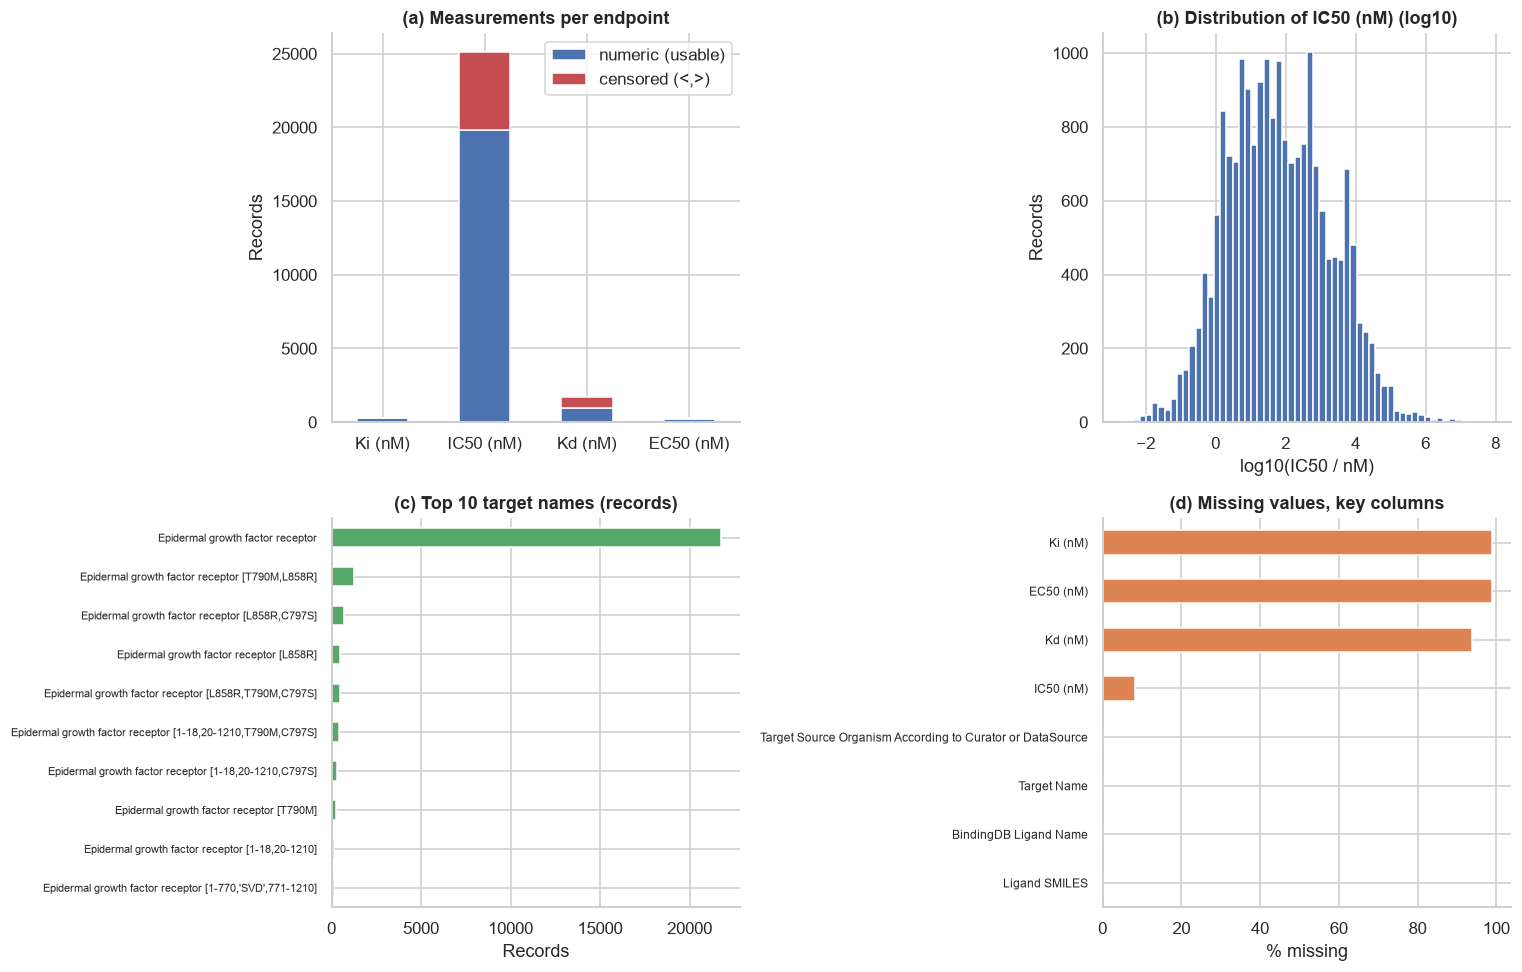

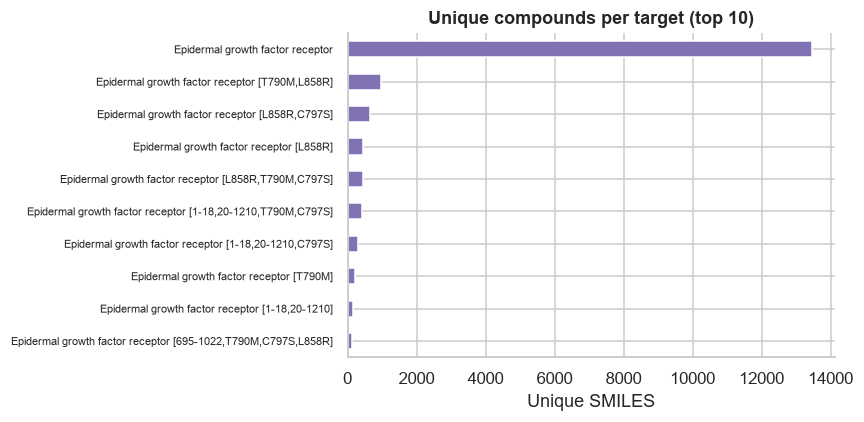

In [7]:
# Target distribution: exact names, and 'base' targets with mutation annotations stripped
df["_BaseTarget"] = df[TARGET_COL].astype(str).str.replace(r"\s*\[.*\]\s*$", "", regex=True)
tgt_counts   = df[TARGET_COL].value_counts()
base_counts  = df["_BaseTarget"].value_counts()
comp_by_tgt  = df.groupby(TARGET_COL)[SMILES_COL].nunique().sort_values(ascending=False)

display(Markdown("**Top 10 exact target names (records)**"))
display(tgt_counts.head(10).rename("records").to_frame())
display(Markdown("**Top 5 base targets (mutation annotation removed)**"))
display((base_counts.head(5).rename("records").to_frame().assign(share_pct=lambda d: (100*d.records/len(df)).round(1))))
if ORG_COL:
    display(Markdown("**Source organism**")); display(df[ORG_COL].value_counts().head(5).rename("records").to_frame())

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
# (a) measurements per endpoint
endpoint_summary[["numeric (usable)", "censored (<,>)"]].plot.bar(stacked=True, ax=axes[0,0], color=[PALETTE[0], PALETTE[3]], rot=0)
axes[0,0].set_title("(a) Measurements per endpoint"); axes[0,0].set_ylabel("Records"); axes[0,0].set_xlabel("")
# (b) distribution of IC50
v = act_numeric[PRIMARY_ENDPOINT]; v = v[v > 0].dropna()
axes[0,1].hist(np.log10(v), bins=60, color=PALETTE[0], edgecolor="white")
axes[0,1].set_title(f"(b) Distribution of {PRIMARY_ENDPOINT} (log10)"); axes[0,1].set_xlabel("log10(IC50 / nM)"); axes[0,1].set_ylabel("Records")
# (c) top targets
tgt_counts.head(10).iloc[::-1].plot.barh(ax=axes[1,0], color=PALETTE[2])
axes[1,0].set_title("(c) Top 10 target names (records)"); axes[1,0].set_xlabel("Records"); axes[1,0].set_ylabel("")
axes[1,0].tick_params(axis="y", labelsize=7)
# (d) missingness of key columns
miss[KEY_COLS].sort_values().plot.barh(ax=axes[1,1], color=PALETTE[1])
axes[1,1].set_title("(d) Missing values, key columns"); axes[1,1].set_xlabel("% missing"); axes[1,1].tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
comp_by_tgt.head(10).iloc[::-1].plot.barh(ax=ax, color=PALETTE[4])
ax.set_title("Unique compounds per target (top 10)"); ax.set_xlabel("Unique SMILES"); ax.set_ylabel(""); ax.tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()

### Does this dataset contain lung-cancer-associated targets?
We screen target names and UniProt recommended names for EGFR and other molecular targets associated with subsets of lung cancer (ALK, KRAS, ROS1, BRAF, MET, RET, ERBB2/HER2, and NTRK). This keyword check is for transparency; matches require manual review of the protein construct, assay, and disease context.

In [8]:
LUNG_CANCER_TARGET_PATTERNS = {
    "EGFR": r"\bEGFR\b|\bERBB1\b|epidermal growth factor receptor",
    "ALK": r"\bALK\b|anaplastic lymphoma kinase",
    "KRAS": r"\bKRAS\b|K-Ras",
    "ROS1": r"\bROS1\b|ROS proto-oncogene 1",
    "BRAF": r"\bBRAF\b|B-Raf",
    "MET": r"\bMET\b|hepatocyte growth factor receptor",
    "RET": r"\bRET\b|ret proto-oncogene",
    "ERBB2/HER2": r"\bERBB2\b|\bHER2\b|erb-b2 receptor tyrosine kinase 2",
    "NTRK": r"\bNTRK[123]\b|neurotrophic receptor tyrosine kinase",
}

def check_lung_cancer_targets(frame, text_cols):
    """Return matches to established lung-cancer-associated targets for manual review."""
    hits = []
    for col in [c for c in text_cols if c]:
        names = frame[col].dropna().astype(str)
        for group, pat in LUNG_CANCER_TARGET_PATTERNS.items():
            matched = names[names.str.contains(pat, flags=re.IGNORECASE, regex=True)]
            for name, count in matched.value_counts().items():
                hits.append({"Target group": group, "matched in column": col, "matched name": name, "records": count})
    return pd.DataFrame(hits)

lung_cancer_hits = check_lung_cancer_targets(df, [TARGET_COL, UNIPROT_COL])
top_base, top_share = base_counts.index[0], 100 * base_counts.iloc[0] / len(df)
LUNG_CANCER_TARGETS_PRESENT = not lung_cancer_hits.empty

if LUNG_CANCER_TARGETS_PRESENT:
    display(Markdown("**Lung-cancer-associated target names found (manual review required):**"))
    display(lung_cancer_hits)
    print("A target-name match alone does not establish cancer indication, tumor context, or clinical efficacy.")
else:
    display(HTML(f"""
    <div style="border:2px solid #c0392b;background:#fdecea;padding:12px;border-radius:6px;color:#611a15">
    <b>Warning: no screened lung-cancer-associated targets were detected.</b><br>
    The supplied dataset is predominantly <b>{top_base}</b> ({top_share:.1f}% of records), but target-name matches alone cannot establish lung-cancer relevance.
    Verify the measured target and assay before interpreting predictions as lung-cancer research.
    </div>"""))

**Lung-cancer-associated target names found (manual review required):**

,Target group,matched in column,matched name,records
0,EGFR,Target Name,Epidermal growth factor receptor,21745
1,EGFR,Target Name,"Epidermal growth factor receptor [T790M,L858R]",1269
2,EGFR,Target Name,"Epidermal growth factor receptor [L858R,C797S]",684
3,EGFR,Target Name,Epidermal growth factor receptor [L858R],479
4,EGFR,Target Name,"Epidermal growth factor receptor [L858R,T790M,...",471
5,EGFR,Target Name,"Epidermal growth factor receptor [1-18,20-1210...",427
6,EGFR,Target Name,"Epidermal growth factor receptor [1-18,20-1210...",330
7,EGFR,Target Name,Epidermal growth factor receptor [T790M],229
8,EGFR,Target Name,"Epidermal growth factor receptor [1-18,20-1210]",150
9,EGFR,Target Name,"Epidermal growth factor receptor [1-770,'SVD',...",146


A target-name match alone does not establish cancer indication, tumor context, or clinical efficacy.


# 4. Identify the Correct Bioactivity Endpoint and Clean the Data
**Primary endpoint:** `IC50 (nM)`. We build a clean modelling table from `Ligand SMILES`, `IC50 (nM)` and `Target Name`, logging how many records are removed at every stage.

Design decisions:
* **Censored values** (`>10000`, `<0.5`) are *not* exact potencies, so they are removed rather than treated as the number after the symbol. (Specialised censored-regression methods could use them; that is out of scope.)
* **Target filter.** Mixing wild-type EGFR with many mutant constructs would blur the SAR, so by default (`TARGET_FILTER="top"`) we keep the single most frequent *exact* target name. Set `TARGET_FILTER=None` to keep every target.
* **Structure standardisation.** SMILES are parsed with RDKit, the largest fragment is kept (removes counter-ions/salts) and the canonical isomeric SMILES is stored. Unparseable structures are removed and counted.

In [9]:
cleaning_log = []
def log_step(stage, n_before, n_after, note=""):
    cleaning_log.append({"stage": stage, "records_before": n_before, "records_removed": n_before - n_after,
                         "records_after": n_after, "note": note})

work = df[[SMILES_COL, PRIMARY_ENDPOINT, TARGET_COL]].copy()
n_original = len(work)
log_step("0. Original records", n_original, n_original)

# 1. missing SMILES
n0 = len(work); work = work[work[SMILES_COL].notna() & (work[SMILES_COL].astype(str).str.strip() != "")]
log_step("1. Missing SMILES", n0, len(work))

# 2. missing IC50
n0 = len(work); work = work[work[PRIMARY_ENDPOINT].notna()]
log_step("2. Missing IC50", n0, len(work))

# 3. non-numeric IC50 (includes censored '<' / '>' qualifiers)
vals, cens = parse_activity(work[PRIMARY_ENDPOINT])
n0 = len(work); n_cens = int(cens.sum())
work[PRIMARY_ENDPOINT] = vals.values
work = work[work[PRIMARY_ENDPOINT].notna()]
log_step("3. Non-numeric IC50", n0, len(work), f"{n_cens:,} are censored values ('<'/'>')")

# 4. IC50 <= 0 (log undefined)
n0 = len(work); work = work[work[PRIMARY_ENDPOINT] > 0]
log_step("4. IC50 <= 0", n0, len(work))

# 5. target filter
n0 = len(work)
if TARGET_FILTER == "top":
    SELECTED_TARGET = work[TARGET_COL].value_counts().index[0]
    work = work[work[TARGET_COL] == SELECTED_TARGET]
elif TARGET_FILTER is None:
    SELECTED_TARGET = None
else:
    if TARGET_FILTER not in set(work[TARGET_COL]):
        raise ValueError(f"TARGET_FILTER '{TARGET_FILTER}' not found among cleaned records.")
    SELECTED_TARGET = TARGET_FILTER; work = work[work[TARGET_COL] == SELECTED_TARGET]
log_step("5. Target filter", n0, len(work), f"kept: {SELECTED_TARGET if SELECTED_TARGET else 'all targets'}")

# 6. RDKit parsing + standardisation (parse each unique SMILES once)
_lfc = rdMolStandardize.LargestFragmentChooser()
def standardize_smiles(smi):
    """Parse -> keep largest fragment -> canonical isomeric SMILES. Returns None if invalid."""
    try:
        mol = Chem.MolFromSmiles(str(smi))
        if mol is None or mol.GetNumAtoms() == 0:
            return None
        mol = _lfc.choose(mol)
        return Chem.MolToSmiles(mol)
    except Exception:
        return None

uniq = work[SMILES_COL].astype(str).unique()
canon_map = {s: standardize_smiles(s) for s in uniq}
work["Canonical_SMILES"] = work[SMILES_COL].astype(str).map(canon_map)
n_invalid_unique = sum(v is None for v in canon_map.values())
n0 = len(work); work = work[work["Canonical_SMILES"].notna()]
log_step("6. RDKit-invalid SMILES", n0, len(work), f"{n_invalid_unique} unique invalid SMILES")
n_valid_structures = len(work)

if MAX_ROWS is not None and work["Canonical_SMILES"].nunique() > MAX_ROWS:   # optional smoke-test subsample
    keep = pd.Series(work["Canonical_SMILES"].unique()).sample(MAX_ROWS, random_state=RANDOM_STATE)
    n0 = len(work); work = work[work["Canonical_SMILES"].isin(set(keep))]
    log_step("6b. MAX_ROWS subsample (debug)", n0, len(work))

work = work.rename(columns={TARGET_COL: "Target Name"}).reset_index(drop=True)
display(pd.DataFrame(cleaning_log).set_index("stage"))
if len(work) < 200:
    raise ValueError(f"Only {len(work)} records remain after cleaning - too few for ML. Check TARGET_FILTER / endpoint.")

,records_before,records_removed,records_after,note
stage,,,,
0. Original records,27399,0,27399,
1. Missing SMILES,27399,0,27399,
2. Missing IC50,27399,2258,25141,
3. Non-numeric IC50,25141,5317,19824,"5,317 are censored values ('<'/'>')"
4. IC50 <= 0,19824,1,19823,
5. Target filter,19823,4441,15382,kept: Epidermal growth factor receptor
6. RDKit-invalid SMILES,15382,3,15379,2 unique invalid SMILES


In [10]:
display(Markdown("**Lung-cancer-associated target check on the cleaned modelling set**"))
lung_cancer_hits_clean = check_lung_cancer_targets(work, ["Target Name"])
print("Targets in the modelling set:", work["Target Name"].unique()[:5], f"({work['Target Name'].nunique()} total)")
print("Lung-cancer-associated target matches:", "none" if lung_cancer_hits_clean.empty else lung_cancer_hits_clean["matched name"].unique().tolist())
print("A target-name match does not establish cancer indication or clinical efficacy.")

**Lung-cancer-associated target check on the cleaned modelling set**

Targets in the modelling set: ['Epidermal growth factor receptor'] (1 total)
Lung-cancer-associated target matches: ['Epidermal growth factor receptor']
A target-name match does not establish cancer indication or clinical efficacy.


# 5. Convert IC50 to pIC50
$$\text{pIC50} = -\log_{10}(\text{IC50 [mol/L]})$$
Because the dataset reports nM (1 nM = 10⁻⁹ M): `pIC50 = 9 - log10(IC50_nM)`.

| IC50 | pIC50 |
|---|---|
| 1 µM = 1000 nM | 6 |
| 100 nM | 7 |
| **10 nM** | **8** |
| 1 nM | 9 |

Lower IC50 (more potent) → higher pIC50. The log scale compresses the huge dynamic range so that models do not focus only on a few extreme values.

,pIC50
count,15379.000
mean,6.963
std,1.385
min,1.081
25%,6.020
50%,7.046
75%,8.000
max,11.699


Skewness: -0.18 | IC50 range: 0.002 - 8.3e+07 nM


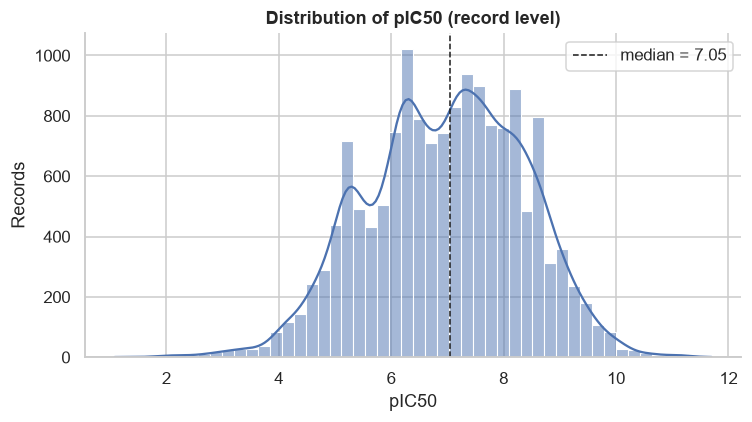

In [11]:
work["pIC50"] = 9 - np.log10(work["IC50 (nM)"])      # IC50 in nM -> pIC50
assert np.isclose(9 - np.log10(10.0), 8.0)           # sanity check from the text: 10 nM -> 8

display(work["pIC50"].describe().round(3).to_frame("pIC50"))
print(f"Skewness: {stats.skew(work['pIC50']):.2f} | IC50 range: {work['IC50 (nM)'].min():.3g} - {work['IC50 (nM)'].max():.3g} nM")

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(work["pIC50"], bins=50, kde=True, color=PALETTE[0], ax=ax)
ax.axvline(work["pIC50"].median(), color="k", ls="--", lw=1, label=f"median = {work['pIC50'].median():.2f}")
ax.set_xlabel("pIC50"); ax.set_ylabel("Records"); ax.set_title("Distribution of pIC50 (record level)"); ax.legend()
plt.tight_layout(); plt.show()

# 6. Data Cleaning and Deduplication
`Canonical_SMILES` was created in Section 4 (largest fragment, canonical, isomeric). Many BindingDB compounds were measured several times (different papers, assays, patents). If these duplicates were split randomly between training and test sets, the model would be evaluated on molecules it has effectively already seen - **duplicate leakage** that inflates test performance.

We therefore (i) quantify the duplication and the within-compound variability and (ii) aggregate to **one row per canonical SMILES using the median pIC50**. The median is robust to outlying assay results. The within-compound spread also gives a rough *noise ceiling*: a model cannot reasonably be expected to be more accurate than the experimental reproducibility.

Records: 15,379 | unique canonical SMILES: 10,307 | records with multi-component SMILES (salts etc.): 63
Compounds with >1 measurement: 2,580 (25.0%) | max measurements for one compound: 198
Within-compound pIC50 SD (replicated compounds): median=0.35, mean=0.47 | share with SD > 1 log unit: 14.6%


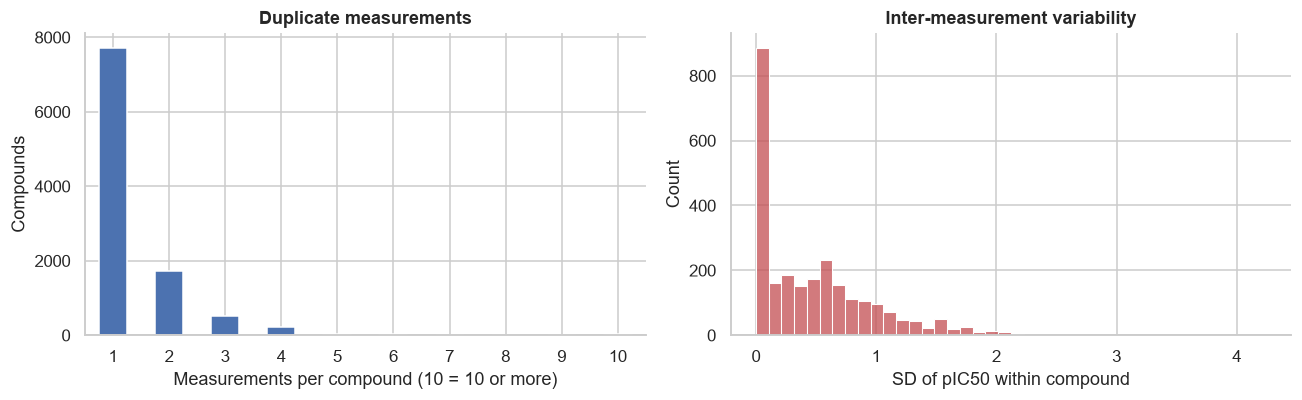

,Canonical_SMILES,pIC50,Target Name,n_measurements,pIC50_std,IC50_nM_median_equiv
0,Brc1cc2c(NCc3ccccc3)ncnc2s1,6.617983,Epidermal growth factor receptor,1,NaN,241.0
1,Brc1cc2c(NCc3ccccn3)ncnc2s1,5.102153,Epidermal growth factor receptor,1,NaN,7904.0
2,Brc1cc2c(NCc3cccs3)ncnc2s1,5.862013,Epidermal growth factor receptor,1,NaN,1374.0
3,Brc1cc2c(NCc3ccncc3)ncnc2s1,5.410833,Epidermal growth factor receptor,1,NaN,3883.0
4,Brc1cc2c(Nc3ccccc3)ncnc2s1,7.096910,Epidermal growth factor receptor,1,NaN,80.0


Final modelling dataframe: (10307, 6)


In [12]:
n_salt = int(work[SMILES_COL].astype(str).str.contains(r"\.").sum())
dup_stats = work.groupby("Canonical_SMILES")["pIC50"].agg(n_measurements="size", pIC50_median="median", pIC50_std="std")
n_unique = len(dup_stats)
print(f"Records: {len(work):,} | unique canonical SMILES: {n_unique:,} | records with multi-component SMILES (salts etc.): {n_salt:,}")
print(f"Compounds with >1 measurement: {(dup_stats.n_measurements>1).sum():,} ({100*(dup_stats.n_measurements>1).mean():.1f}%) | max measurements for one compound: {dup_stats.n_measurements.max()}")
rep = dup_stats[dup_stats.n_measurements > 1]
print(f"Within-compound pIC50 SD (replicated compounds): median={rep.pIC50_std.median():.2f}, mean={rep.pIC50_std.mean():.2f} "
      f"| share with SD > 1 log unit: {100*(rep.pIC50_std>1).mean():.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
dup_stats.n_measurements.clip(upper=10).value_counts().sort_index().plot.bar(ax=axes[0], color=PALETTE[0], rot=0)
axes[0].set_xlabel("Measurements per compound (10 = 10 or more)"); axes[0].set_ylabel("Compounds"); axes[0].set_title("Duplicate measurements")
sns.histplot(rep.pIC50_std.dropna(), bins=40, ax=axes[1], color=PALETTE[3])
axes[1].set_xlabel("SD of pIC50 within compound"); axes[1].set_title("Inter-measurement variability")
plt.tight_layout(); plt.show()

# Final modelling dataframe: one row per compound, median pIC50
target_mode = work.groupby("Canonical_SMILES")["Target Name"].agg(lambda s: s.value_counts().index[0])
model_df = (dup_stats.reset_index()[["Canonical_SMILES", "pIC50_median", "n_measurements", "pIC50_std"]]
            .rename(columns={"pIC50_median": "pIC50"}))
model_df["Target Name"] = model_df["Canonical_SMILES"].map(target_mode)
model_df["IC50_nM_median_equiv"] = 10 ** (9 - model_df["pIC50"])
model_df = model_df[["Canonical_SMILES", "pIC50", "Target Name", "n_measurements", "pIC50_std", "IC50_nM_median_equiv"]].reset_index(drop=True)
display(model_df.head()); print("Final modelling dataframe:", model_df.shape)

# 7. Molecular Descriptor Generation Using RDKit
Interpretable physicochemical descriptors are computed for every molecule: molecular weight, Crippen logP, TPSA, H-bond donors/acceptors, rotatable bonds, ring and aromatic-ring counts, fraction Csp3, heavy-atom count, formal charge, plus Labute ASA, molar refractivity, heteroatom count and QED as additional size/polarity/drug-likeness proxies.

*Molecular volume:* RDKit's `AllChem.ComputeMolVolume` needs a 3D conformer (embedding ≈ 0.1 s/molecule), which is impractical for thousands of molecules on Colab. It is optional (`COMPUTE_3D_VOLUME=True`); by default Labute ASA and molar refractivity serve as size proxies.

Problems handled below: `NaN`, `±inf` and constant (zero-variance) descriptors. Descriptors are computed per molecule independently, so this step cannot leak label or split information. Median imputation and standardisation are **fitted on the training set only** in Section 9.

In [13]:
def mol_volume_3d(mol):
    """Optional 3D van-der-Waals volume (A^3); NaN if embedding fails."""
    try:
        mh = Chem.AddHs(mol)
        if AllChem.EmbedMolecule(mh, randomSeed=RANDOM_STATE) != 0:
            return np.nan
        return AllChem.ComputeMolVolume(mh)
    except Exception:
        return np.nan

DESCRIPTOR_FUNCS = {
    "MolWt":            Descriptors.MolWt,
    "LogP":             Crippen.MolLogP,
    "TPSA":             rdMolDescriptors.CalcTPSA,
    "HBD":              Lipinski.NumHDonors,
    "HBA":              Lipinski.NumHAcceptors,
    "RotatableBonds":   Lipinski.NumRotatableBonds,
    "RingCount":        rdMolDescriptors.CalcNumRings,
    "AromaticRings":    rdMolDescriptors.CalcNumAromaticRings,
    "FractionCSP3":     rdMolDescriptors.CalcFractionCSP3,
    "HeavyAtomCount":   lambda m: m.GetNumHeavyAtoms(),
    "FormalCharge":     Chem.GetFormalCharge,
    "LabuteASA":        rdMolDescriptors.CalcLabuteASA,
    "MolMR":            Crippen.MolMR,
    "NumHeteroatoms":   rdMolDescriptors.CalcNumHeteroatoms,
    "QED":              QED.qed,
}
if COMPUTE_3D_VOLUME:
    DESCRIPTOR_FUNCS["MolVolume3D"] = mol_volume_3d

def compute_descriptors(mol):
    """All descriptors for one molecule; a failing descriptor becomes NaN instead of crashing the pipeline."""
    out = {}
    for name, fn in DESCRIPTOR_FUNCS.items():
        try:
            out[name] = float(fn(mol))
        except Exception:
            out[name] = np.nan
    return out

mols = [Chem.MolFromSmiles(s) for s in model_df["Canonical_SMILES"]]
assert all(m is not None for m in mols), "Canonical SMILES failed to re-parse"

t0 = time.time()
desc_raw = pd.DataFrame([compute_descriptors(m) for m in mols])
print(f"Computed {desc_raw.shape[1]} descriptors for {len(desc_raw):,} molecules in {time.time()-t0:.1f}s")

# Handle inf / NaN / constants
desc_raw = desc_raw.replace([np.inf, -np.inf], np.nan)
print("NaN per descriptor:", desc_raw.isna().sum()[lambda s: s > 0].to_dict() or "none")
all_nan = desc_raw.columns[desc_raw.isna().all()].tolist()
constant = [c for c in desc_raw.columns if c not in all_nan and desc_raw[c].nunique(dropna=True) <= 1]
if all_nan or constant:
    print("Dropping all-NaN:", all_nan, "| constant:", constant)
desc_raw = desc_raw.drop(columns=all_nan + constant)
DESC_COLS = desc_raw.columns.tolist()
display(desc_raw.describe().T.round(2))

Computed 15 descriptors for 10,307 molecules in 47.1s
NaN per descriptor: none


,count,mean,std,min,25%,50%,75%,max
MolWt,10307.0,484.19,121.66,130.15,402.25,486.52,559.63,1425.80
LogP,10307.0,4.58,1.43,-6.04,3.67,4.56,5.48,13.12
TPSA,10307.0,96.84,30.82,6.48,77.53,97.40,112.08,484.16
HBD,10307.0,2.22,1.20,0.00,1.00,2.00,3.00,15.00
HBA,10307.0,6.82,2.19,1.00,5.00,7.00,8.00,19.00
RotatableBonds,10307.0,6.95,3.19,0.00,5.00,7.00,9.00,36.00
RingCount,10307.0,4.45,1.35,0.00,4.00,4.00,5.00,11.00
AromaticRings,10307.0,3.55,0.94,0.00,3.00,4.00,4.00,9.00
FractionCSP3,10307.0,0.24,0.13,0.00,0.14,0.24,0.32,0.93
HeavyAtomCount,10307.0,34.14,8.67,10.00,28.00,34.00,40.00,103.00


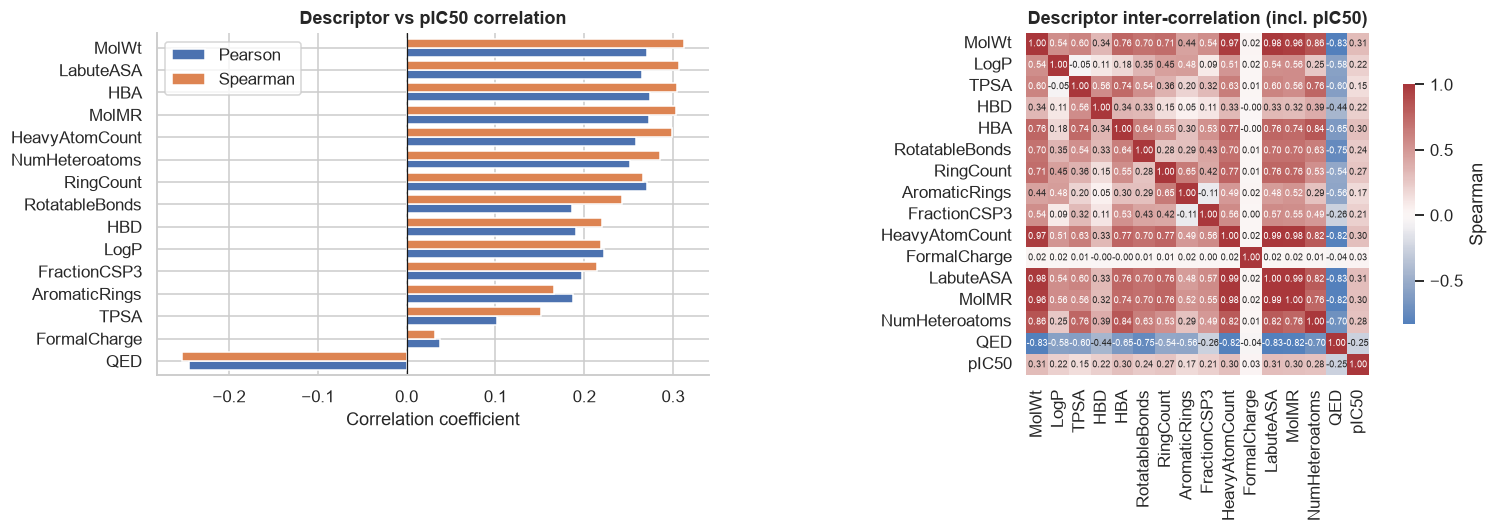

Note: correlations are modest, which is typical - single physicochemical properties rarely explain potency; substructure information (fingerprints) matters.


In [14]:
# Exploratory association between descriptors and pIC50 (no feature selection is based on this)
y_all = model_df["pIC50"].to_numpy()
corr = pd.DataFrame({
    "Pearson":  [stats.pearsonr(desc_raw[c].fillna(desc_raw[c].median()), y_all)[0] for c in DESC_COLS],
    "Spearman": [stats.spearmanr(desc_raw[c].fillna(desc_raw[c].median()), y_all)[0] for c in DESC_COLS],
}, index=DESC_COLS).sort_values("Spearman")

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.25]})
corr.plot.barh(ax=axes[0], color=[PALETTE[0], PALETTE[1]], width=0.8)
axes[0].axvline(0, color="k", lw=0.8); axes[0].set_title("Descriptor vs pIC50 correlation"); axes[0].set_xlabel("Correlation coefficient")
cm = pd.concat([desc_raw, model_df["pIC50"]], axis=1).corr(method="spearman")
sns.heatmap(cm, cmap="vlag", center=0, annot=len(cm) <= 20, fmt=".2f", annot_kws={"size": 6}, square=True,
            cbar_kws={"shrink": .7, "label": "Spearman"}, ax=axes[1])
axes[1].set_title("Descriptor inter-correlation (incl. pIC50)")
plt.tight_layout(); plt.show()
print("Note: correlations are modest, which is typical - single physicochemical properties rarely explain potency; substructure information (fingerprints) matters.")

# 8. Morgan Fingerprints
Morgan (circular) fingerprints encode each atom's neighbourhood up to a given radius (here 2, similar to ECFP4) and hash it to one of 2048 bits. Bit *i* = 1 means a substructure hashing to *i* is present. Caveat: hash collisions mean one bit can represent several substructures.

The requested call `AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=2048)` is **deprecated** in recent RDKit releases. We use the modern `rdFingerprintGenerator` API, and the next cell verifies it produces identical bits.

In [15]:
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, fpSize=N_BITS)

def fp_bitvect(mol):
    return morgan_gen.GetFingerprint(mol)

def fp_to_numpy(fp):
    arr = np.zeros((N_BITS,), dtype=np.uint8)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

# Consistency check against the legacy call requested in the brief (skipped silently if removed from RDKit)
try:
    same = all(
        list(AllChem.GetMorganFingerprintAsBitVect(m, MORGAN_RADIUS, nBits=N_BITS).GetOnBits()) == list(fp_bitvect(m).GetOnBits())
        for m in mols[:100])
    print("Legacy GetMorganFingerprintAsBitVect == rdFingerprintGenerator on 100 molecules:", same)
except Exception as e:
    print("Legacy API not available in this RDKit version - using rdFingerprintGenerator only.", type(e).__name__)

fps = [fp_bitvect(m) for m in mols]                                   # kept for Tanimoto similarity
X_fp = np.vstack([fp_to_numpy(f) for f in fps]).astype(np.float32)    # (n_molecules, 2048)
FP_COLS = [f"Morgan_{i}" for i in range(N_BITS)]
print(f"Fingerprint matrix: {X_fp.shape} | mean bits set per molecule: {X_fp.sum(1).mean():.1f} | bits never set: {(X_fp.sum(0)==0).sum()}")

Legacy GetMorganFingerprintAsBitVect == rdFingerprintGenerator on 100 molecules: True
Fingerprint matrix: (10307, 2048) | mean bits set per molecule: 62.3 | bits never set: 0


# 9. Train/Test Split (scaffold-aware)
**Why not a random split?** Medicinal-chemistry datasets consist of *series* of close analogues that share a core (Bemis–Murcko scaffold). A random split puts near-identical analogues on both sides, so test performance largely measures interpolation between neighbours and is optimistic compared with predicting genuinely new chemotypes (**scaffold/analogue leakage**). Duplicate measurements of the same molecule are an even more direct leak (handled in Section 6).

We therefore use a **scaffold split**: all compounds sharing a Bemis–Murcko scaffold go entirely to either train or test. Large scaffold groups are assigned to training first and the remaining groups are shuffled (seeded) - the "balanced scaffold split" used by e.g. Chemprop, so that the test set is not made up only of rare singletons. Scaffold splitting is stricter but still not perfect (different scaffolds can be similar; Section 17 quantifies this).

Leakage controls in this notebook: (1) one row per canonical SMILES; (2) scaffold-disjoint split; (3) imputer/scaler fitted on **training data only**; (4) model *selection* uses cross-validation on training data (grouped by scaffold), not the test set; (5) the test set is used once for the final evaluation.

In [16]:
def murcko_scaffold(smi):
    """Bemis-Murcko scaffold SMILES; acyclic molecules are their own group (avoids one giant '' group)."""
    try:
        sc = MurckoScaffold.MurckoScaffoldSmiles(smiles=smi, includeChirality=False)
        return sc if sc else smi
    except Exception:
        return smi

def scaffold_split_indices(scaffolds, test_size=0.2, seed=42):
    """Balanced scaffold split. Returns (train_idx, test_idx) with no scaffold shared between them."""
    rng = np.random.RandomState(seed)
    groups = defaultdict(list)
    for i, s in enumerate(scaffolds):
        groups[s].append(i)
    sets = list(groups.values())
    n = len(scaffolds); n_test = int(round(test_size * n)); n_train_target = n - n_test
    big   = [s for s in sets if len(s) > n_test / 2]
    small = [s for s in sets if len(s) <= n_test / 2]
    rng.shuffle(big); rng.shuffle(small)
    train, test = [], []
    for s in big + small:
        (train if len(train) + len(s) <= n_train_target else test).extend(s)
    return np.array(sorted(train)), np.array(sorted(test))

def max_sim_to_reference(query_fps, ref_fps, k=5):
    """Max Tanimoto and mean of top-k Tanimoto of each query fingerprint against a reference set."""
    mx, mk = np.zeros(len(query_fps)), np.zeros(len(query_fps))
    for i, f in enumerate(query_fps):
        s = np.asarray(DataStructs.BulkTanimotoSimilarity(f, ref_fps))
        kk = min(k, len(s)); top = np.partition(s, -kk)[-kk:]
        mx[i], mk[i] = s.max(), top.mean()
    return mx, mk

model_df["Scaffold"] = [murcko_scaffold(s) for s in model_df["Canonical_SMILES"]]
train_idx, test_idx = scaffold_split_indices(model_df["Scaffold"].tolist(), TEST_SIZE, RANDOM_STATE)

# ---- leakage checks ----
assert set(model_df.Scaffold.iloc[train_idx]).isdisjoint(model_df.Scaffold.iloc[test_idx]), "scaffold overlap!"
assert set(model_df.Canonical_SMILES.iloc[train_idx]).isdisjoint(model_df.Canonical_SMILES.iloc[test_idx]), "molecule overlap!"
print(f"Train: {len(train_idx):,} | Test: {len(test_idx):,} ({100*len(test_idx)/len(model_df):.1f}%) | "
      f"scaffolds: {model_df.Scaffold.iloc[train_idx].nunique():,} train / {model_df.Scaffold.iloc[test_idx].nunique():,} test (disjoint)")
print(f"pIC50 mean+-SD  train: {y_all[train_idx].mean():.2f}+-{y_all[train_idx].std():.2f} | test: {y_all[test_idx].mean():.2f}+-{y_all[test_idx].std():.2f}")

# ---- preprocessing fitted on TRAIN only ----
imputer = SimpleImputer(strategy="median").fit(desc_raw.iloc[train_idx])
desc_imp = pd.DataFrame(imputer.transform(desc_raw), columns=DESC_COLS, index=desc_raw.index)
scaler = StandardScaler().fit(desc_imp.iloc[train_idx])
desc_scaled = pd.DataFrame(scaler.transform(desc_imp), columns=DESC_COLS, index=desc_raw.index)   # for linear/NN models; trees are scale-invariant

X_desc = desc_imp.to_numpy(dtype=np.float32)
X_comb = np.hstack([X_desc, X_fp])                       # descriptors + Morgan bits
FEATURE_NAMES = DESC_COLS + FP_COLS
FEATURE_SETS = {"Descriptors only": X_desc, "Fingerprint only": X_fp, "Descriptors + Fingerprint": X_comb}

y = y_all
X_train, X_test = X_comb[train_idx], X_comb[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
groups_train = pd.factorize(model_df["Scaffold"].iloc[train_idx])[0]
fps_train = [fps[i] for i in train_idx]; fps_test = [fps[i] for i in test_idx]
print("Combined feature matrix:", X_comb.shape, f"({len(DESC_COLS)} descriptors + {N_BITS} bits)")

Train: 8,246 | Test: 2,061 (20.0%) | scaffolds: 2,891 train / 770 test (disjoint)
pIC50 mean+-SD  train: 6.86+-1.38 | test: 6.93+-1.31
Combined feature matrix: (10307, 2063) (15 descriptors + 2048 bits)


# 10. Baseline Model - Random Forest
A Random Forest averages many decorrelated decision trees. Metrics: **R²** (variance explained), **RMSE** (penalises large errors, in pIC50 units) and **MAE** (typical absolute error). An RMSE of 0.7 means predictions are typically within ~0.7 log units (≈5-fold in IC50).

For practicality, each split considers a random 20% of the ~2,000 features (`max_features=0.2`); otherwise the other settings are those requested (500 trees, seed 42).

In [17]:
def regression_metrics(y_true, y_pred):
    return {"R2": r2_score(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "MAE": mean_absolute_error(y_true, y_pred)}

def plot_pred_vs_actual(y_true, y_pred, title, ax=None, color=None):
    ax = ax or plt.subplots(figsize=(5, 5))[1]
    m = regression_metrics(y_true, y_pred)
    ax.scatter(y_true, y_pred, s=10, alpha=0.35, color=color or PALETTE[0], edgecolor="none")
    lo, hi = min(y_true.min(), y_pred.min()) - 0.3, max(y_true.max(), y_pred.max()) + 0.3
    ax.plot([lo, hi], [lo, hi], "k--", lw=1); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
    ax.set_xlabel("Experimental pIC50"); ax.set_ylabel("Predicted pIC50"); ax.set_title(title)
    ax.text(0.04, 0.96, f"R$^2$ = {m['R2']:.3f}\nRMSE = {m['RMSE']:.3f}\nMAE = {m['MAE']:.3f}", transform=ax.transAxes, va="top",
            bbox=dict(boxstyle="round", fc="white", ec="0.8"))
    return ax

models, test_preds, metric_rows = {}, {}, []

def fit_and_evaluate(name, model, Xtr=None, Xte=None):
    """Fit on the training set, evaluate once on the held-out scaffold test set."""
    Xtr = X_train if Xtr is None else Xtr; Xte = X_test if Xte is None else Xte
    t0 = time.time(); model.fit(Xtr, y_train); dt = time.time() - t0
    pred = model.predict(Xte)
    models[name], test_preds[name] = model, pred
    metric_rows[:] = [r for r in metric_rows if r["Model"] != name]
    metric_rows.append({"Model": name, **regression_metrics(y_test, pred), "Train time (s)": round(dt, 1)})
    print(f"{name}: " + ", ".join(f"{k}={v:.3f}" for k, v in regression_metrics(y_test, pred).items()) + f"  ({dt:.0f}s)")
    return model, pred

rf = RandomForestRegressor(n_estimators=500, max_features=RF_MAX_FEATURES, random_state=RANDOM_STATE, n_jobs=N_JOBS)
rf, rf_pred = fit_and_evaluate("Random Forest", rf)

Random Forest: R2=0.626, RMSE=0.801, MAE=0.601  (51s)


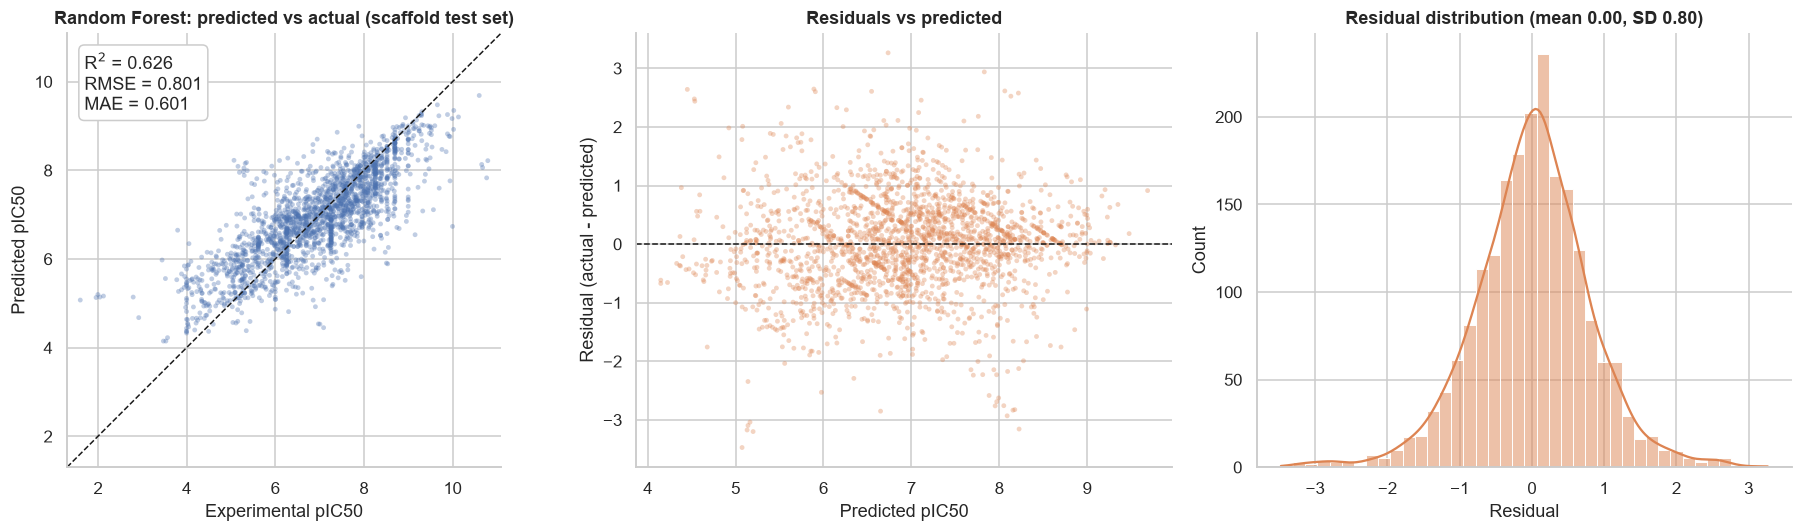

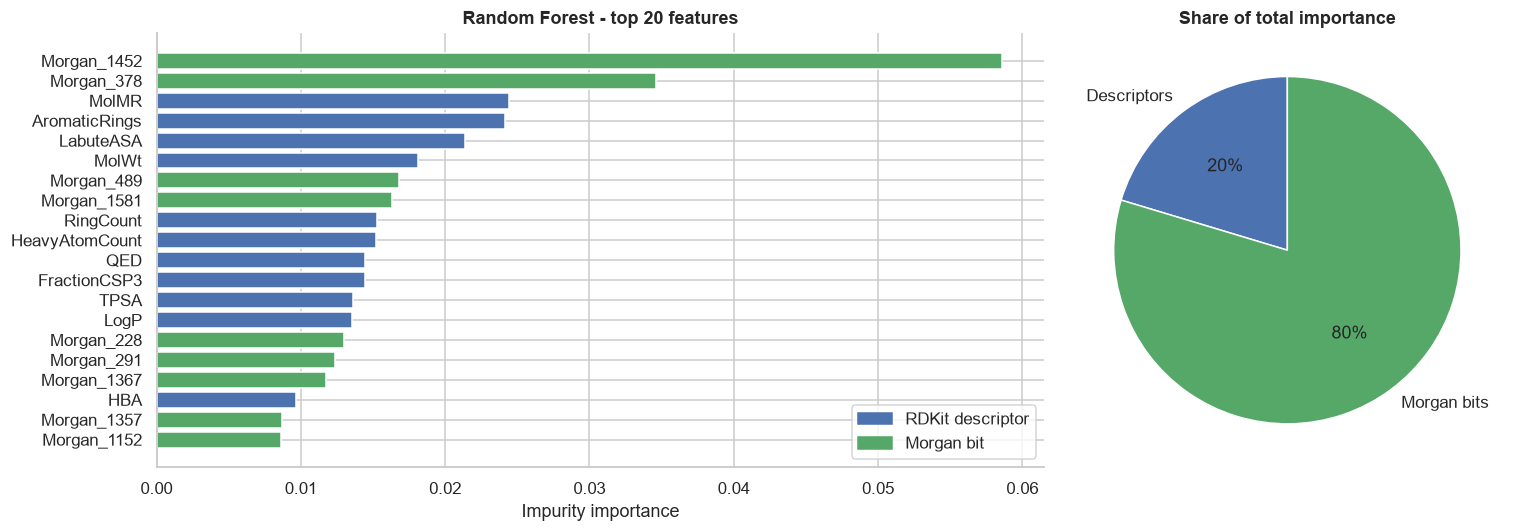

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
plot_pred_vs_actual(y_test, rf_pred, "Random Forest: predicted vs actual (scaffold test set)", ax=axes[0])
resid = y_test - rf_pred
axes[1].scatter(rf_pred, resid, s=10, alpha=0.35, color=PALETTE[1], edgecolor="none"); axes[1].axhline(0, color="k", ls="--", lw=1)
axes[1].set_xlabel("Predicted pIC50"); axes[1].set_ylabel("Residual (actual - predicted)"); axes[1].set_title("Residuals vs predicted")
sns.histplot(resid, bins=40, kde=True, ax=axes[2], color=PALETTE[1]); axes[2].set_xlabel("Residual"); axes[2].set_title(f"Residual distribution (mean {resid.mean():.2f}, SD {resid.std():.2f})")
plt.tight_layout(); plt.show()

# Feature importance (impurity-based; biased towards high-cardinality features, so interpret cautiously)
imp_df = pd.Series(rf.feature_importances_, index=FEATURE_NAMES).sort_values(ascending=False)
top20 = imp_df.head(20).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2, 1]})
axes[0].barh(top20.index, top20.values, color=[PALETTE[0] if n in DESC_COLS else PALETTE[2] for n in top20.index])
axes[0].set_title("Random Forest - top 20 features"); axes[0].set_xlabel("Impurity importance")
axes[0].legend(handles=[plt.Rectangle((0,0),1,1,color=PALETTE[0]), plt.Rectangle((0,0),1,1,color=PALETTE[2])], labels=["RDKit descriptor", "Morgan bit"], loc="lower right")
grp = pd.Series({"Descriptors": imp_df[DESC_COLS].sum(), "Morgan bits": imp_df[FP_COLS].sum()})
axes[1].pie(grp, labels=grp.index, autopct="%1.0f%%", colors=[PALETTE[0], PALETTE[2]], startangle=90); axes[1].set_title("Share of total importance")
plt.tight_layout(); plt.show()

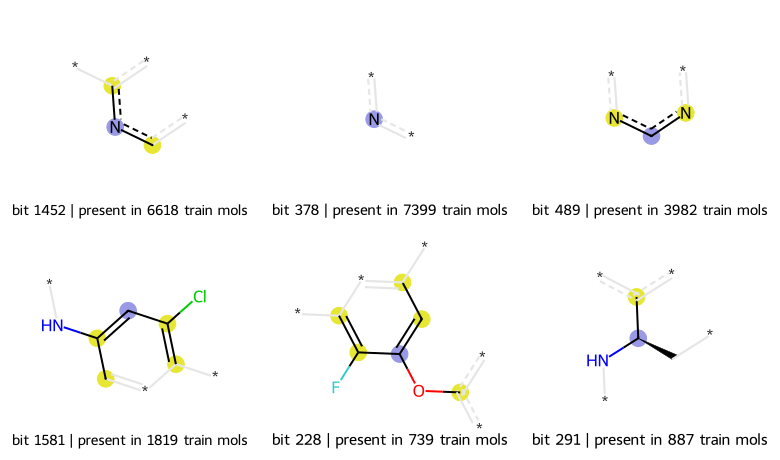

Highlighted atoms show the substructure (radius <= 2) hashed to each bit, shown in one example molecule. Because of hash collisions and correlated bits, treat these as hints, not definitive pharmacophores.


In [19]:
# Which substructures do the most important Morgan bits represent? (examples from the training set)
def draw_important_bits(importances, n_bits_to_show=6):
    top_bits = [int(n.split("_")[1]) for n in importances.index if n.startswith("Morgan_")][:n_bits_to_show]
    tuples, legends = [], []
    for b in top_bits:
        rows_with_bit = np.where(X_fp[train_idx, b] == 1)[0]
        if len(rows_with_bit) == 0:
            continue
        m = mols[train_idx[rows_with_bit[0]]]
        ao = rdFingerprintGenerator.AdditionalOutput(); ao.AllocateBitInfoMap()
        morgan_gen.GetFingerprint(m, additionalOutput=ao)
        tuples.append((m, b, ao.GetBitInfoMap())); legends.append(f"bit {b} | present in {int(X_fp[train_idx, b].sum())} train mols")
    return Draw.DrawMorganBits(tuples, molsPerRow=3, subImgSize=(260, 230), legends=legends)

try:
    display(draw_important_bits(imp_df))
    print("Highlighted atoms show the substructure (radius <= 2) hashed to each bit, shown in one example molecule. "
          "Because of hash collisions and correlated bits, treat these as hints, not definitive pharmacophores.")
except Exception as e:
    print("Substructure drawing skipped:", type(e).__name__, e)

# 11. LightGBM Model
Gradient boosting builds trees sequentially, each correcting the errors of the ensemble so far. LightGBM uses histogram-based, leaf-wise growth and is fast on wide feature matrices.

LightGBM: R2=0.616, RMSE=0.812, MAE=0.609  (4s)


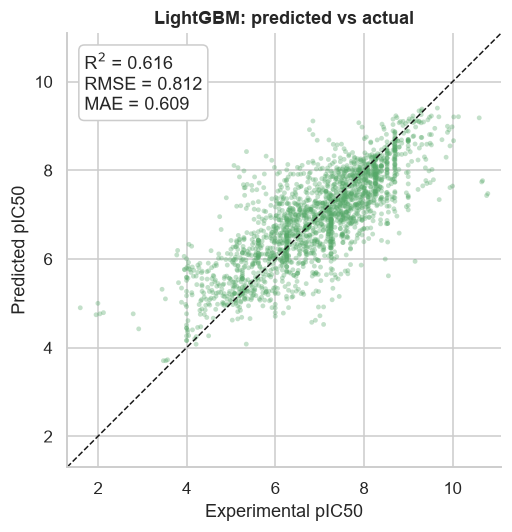

In [20]:
lgbm = LGBMRegressor(n_estimators=500, learning_rate=0.05, max_depth=-1, num_leaves=31,
                     random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=-1)
lgbm, lgbm_pred = fit_and_evaluate("LightGBM", lgbm)
plot_pred_vs_actual(y_test, lgbm_pred, "LightGBM: predicted vs actual", color=PALETTE[2]); plt.tight_layout(); plt.show()

# 12. XGBoost Model
XGBoost is a regularised gradient-boosting implementation with depth-wise tree growth (`max_depth=6`) and row/column subsampling (0.8) to reduce over-fitting.

XGBoost: R2=0.613, RMSE=0.815, MAE=0.617  (13s)


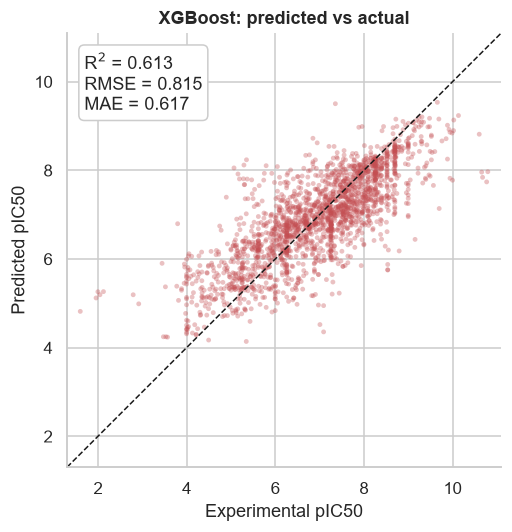

In [21]:
xgb = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
                   random_state=RANDOM_STATE, objective="reg:squarederror", tree_method="hist", n_jobs=N_JOBS)
xgb, xgb_pred = fit_and_evaluate("XGBoost", xgb)
plot_pred_vs_actual(y_test, xgb_pred, "XGBoost: predicted vs actual", color=PALETTE[3]); plt.tight_layout(); plt.show()

# 13. Model Comparison
All three models share the **same scaffold-disjoint test set**, so the comparison is paired. A single test split is, however, one sample of chemical space: small metric differences may be within noise. We therefore add bootstrap 95% intervals (resampling test molecules) and compare against a **random split** to show how much optimism analogue leakage introduces.

,R²,RMSE,MAE,Train time (s)
Model,,,,
Random Forest,0.626,0.801,0.601,51.4
LightGBM,0.616,0.812,0.609,3.9
XGBoost,0.613,0.815,0.617,12.8


,R² 95% CI,RMSE 95% CI
Model,,
Random Forest,"[0.598, 0.653]","[0.769, 0.831]"
LightGBM,"[0.587, 0.643]","[0.781, 0.844]"
XGBoost,"[0.586, 0.640]","[0.782, 0.846]"


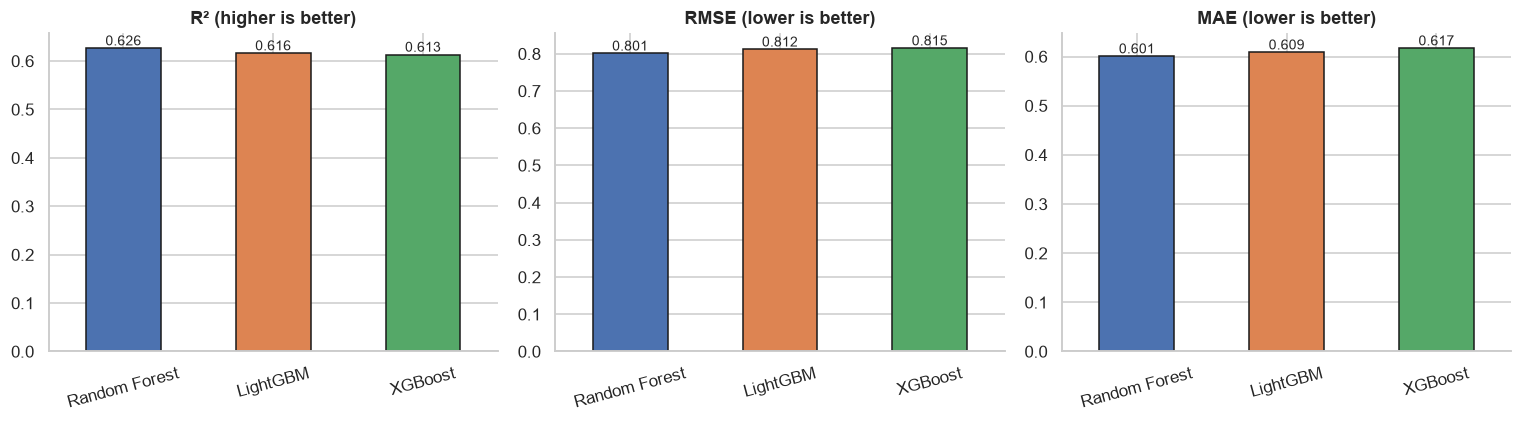

**Reading the table.** Best by R²: **Random Forest**; by RMSE: **Random Forest**; by MAE: **Random Forest**. The RMSE spread across models is 0.014 pIC50 units. R² is relative to the variance of the test set, RMSE emphasises large errors (outliers, activity cliffs) and MAE reflects the typical error, so the metrics can rank models differently. If bootstrap intervals overlap, the data do not support declaring a single winner from this one split; model selection later in this notebook is therefore based on grouped cross-validation on the training set.

In [22]:
BASE_MODELS = ["Random Forest", "LightGBM", "XGBoost"]
comparison_df = pd.DataFrame(metric_rows).set_index("Model").loc[BASE_MODELS].rename(columns={"R2": "R²"})
display(comparison_df.round(3))

def bootstrap_ci(y_true, y_pred, n=500, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed); r2s, rmses = [], []
    for _ in range(n):
        i = rng.randint(0, len(y_true), len(y_true))
        r2s.append(r2_score(y_true[i], y_pred[i])); rmses.append(np.sqrt(mean_squared_error(y_true[i], y_pred[i])))
    return np.percentile(r2s, [2.5, 97.5]), np.percentile(rmses, [2.5, 97.5])
ci_rows = []
for m in BASE_MODELS:
    r2ci, rmseci = bootstrap_ci(y_test, test_preds[m])
    ci_rows.append({"Model": m, "R² 95% CI": f"[{r2ci[0]:.3f}, {r2ci[1]:.3f}]", "RMSE 95% CI": f"[{rmseci[0]:.3f}, {rmseci[1]:.3f}]"})
display(pd.DataFrame(ci_rows).set_index("Model"))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric, better in zip(axes, ["R²", "RMSE", "MAE"], ["higher", "lower", "lower"]):
    comparison_df[metric].plot.bar(ax=ax, color=PALETTE[:3], rot=15, edgecolor="k")
    ax.set_title(f"{metric} ({better} is better)"); ax.set_xlabel("")
    for p in ax.patches: ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

best_by = {"R²": comparison_df["R²"].idxmax(), "RMSE": comparison_df["RMSE"].idxmin(), "MAE": comparison_df["MAE"].idxmin()}
spread_rmse = comparison_df["RMSE"].max() - comparison_df["RMSE"].min()
display(Markdown(
    f"**Reading the table.** Best by R²: **{best_by['R²']}**; by RMSE: **{best_by['RMSE']}**; by MAE: **{best_by['MAE']}**. "
    f"The RMSE spread across models is {spread_rmse:.3f} pIC50 units. "
    "R² is relative to the variance of the test set, RMSE emphasises large errors (outliers, activity cliffs) and MAE reflects the typical error, "
    "so the metrics can rank models differently. If bootstrap intervals overlap, the data do not support declaring a single winner from this one split; "
    "model selection later in this notebook is therefore based on grouped cross-validation on the training set."))

In [23]:
# (a) Descriptor-only vs fingerprint-only vs combined (LightGBM, fast)   (b) random split vs scaffold split
fs_rows = []
for fs_name, Xfs in FEATURE_SETS.items():
    m = LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=-1)
    m.fit(Xfs[train_idx], y_train); fs_rows.append({"Feature set": fs_name, "Split": "scaffold", **regression_metrics(y_test, m.predict(Xfs[test_idx]))})

rtr, rte = train_test_split(np.arange(len(model_df)), test_size=TEST_SIZE, random_state=RANDOM_STATE)
m = LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=-1).fit(X_comb[rtr], y[rtr])
fs_rows.append({"Feature set": "Descriptors + Fingerprint", "Split": "random", **regression_metrics(y[rte], m.predict(X_comb[rte]))})
display(pd.DataFrame(fs_rows).set_index(["Feature set", "Split"]).round(3))

sim_scaf, _ = max_sim_to_reference(fps_test, fps_train)
sim_rand, _ = max_sim_to_reference([fps[i] for i in rte], [fps[i] for i in rtr])
print(f"Median max-Tanimoto of test molecules to training set - scaffold split: {np.median(sim_scaf):.2f} | random split: {np.median(sim_rand):.2f}")
print("A random split typically gives higher similarity and better-looking metrics: that difference is the leakage a random split hides.")

R2   RMSE    MAE
Feature set               Split                        
Descriptors only          scaffold  0.306  1.092  0.850
Fingerprint only          scaffold  0.596  0.832  0.625
Descriptors + Fingerprint scaffold  0.603  0.825  0.624
                          random    0.712  0.739  0.557

Median max-Tanimoto of test molecules to training set - scaffold split: 0.74 | random split: 0.82
A random split typically gives higher similarity and better-looking metrics: that difference is the leakage a random split hides.


# 14. Cross-Validation
5-fold cross-validation **on the training set**, with folds grouped by Bemis-Murcko scaffold (`GroupKFold`) so that CV is subject to the same no-analogue-leakage rule as the final test. The held-out test set is not touched. Mean ± SD across folds is reported for R², RMSE and MAE.

In [24]:
cv = GroupKFold(n_splits=5)
scoring = {"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}
cv_rows, cv_store = [], {}
for name in BASE_MODELS:
    t0 = time.time()
    res = cross_validate(clone(models[name]), X_train, y_train, groups=groups_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_store[name] = res
    cv_rows.append({"Model": name,
                    "R² mean": res["test_r2"].mean(), "R² SD": res["test_r2"].std(),
                    "RMSE mean": -res["test_rmse"].mean(), "RMSE SD": res["test_rmse"].std(),
                    "MAE mean": -res["test_mae"].mean(), "MAE SD": res["test_mae"].std()})
    print(f"{name}: CV done in {time.time()-t0:.0f}s")
cv_df = pd.DataFrame(cv_rows).set_index("Model")
display(cv_df.round(3))

Random Forest: CV done in 198s
LightGBM: CV done in 15s
XGBoost: CV done in 39s


,R² mean,R² SD,RMSE mean,RMSE SD,MAE mean,MAE SD
Model,,,,,,
Random Forest,0.604,0.045,0.860,0.032,0.651,0.018
LightGBM,0.584,0.042,0.882,0.026,0.670,0.018
XGBoost,0.581,0.043,0.885,0.028,0.676,0.019


# 15. Hyperparameter Optimization
`RandomizedSearchCV` (a few random draws per model, scaffold-grouped CV, RMSE objective) is used to keep run-time practical. To stay Colab-friendly the search runs on a random subsample of the **training** set (`SEARCH_MAX_ROWS`); the best configuration is then refitted on the *full* training set. Raise `SEARCH_N_ITER`, `SEARCH_CV` and `SEARCH_MAX_ROWS` for a more thorough search. Models are *selected by cross-validated RMSE*, never by test score.

In [25]:
search_spaces = {
    "Random Forest": (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS), {
        "n_estimators": randint(200, 501), "max_depth": [None, 10, 20, 30], "min_samples_split": randint(2, 11),
        "min_samples_leaf": randint(1, 6), "max_features": [0.1, 0.2, 0.33, "sqrt"]}),
    "LightGBM": (LGBMRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=-1, subsample_freq=1), {
        "n_estimators": randint(200, 801), "learning_rate": uniform(0.02, 0.13), "num_leaves": randint(15, 128),
        "max_depth": [-1, 6, 10, 15], "min_child_samples": randint(5, 50), "subsample": uniform(0.6, 0.4),
        "colsample_bytree": uniform(0.3, 0.7)}),
    "XGBoost": (XGBRegressor(random_state=RANDOM_STATE, objective="reg:squarederror", tree_method="hist", n_jobs=N_JOBS), {
        "n_estimators": randint(200, 801), "learning_rate": uniform(0.02, 0.13), "max_depth": randint(3, 10),
        "min_child_weight": randint(1, 8), "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.3, 0.7)}),
}

rng = np.random.RandomState(RANDOM_STATE)
sub = np.sort(rng.choice(len(X_train), min(SEARCH_MAX_ROWS, len(X_train)), replace=False))
tuning_rows, best_params, tuned_cv_rmse = [], {}, {}
for name, (est, space) in search_spaces.items():
    t0 = time.time()
    rs = RandomizedSearchCV(est, space, n_iter=SEARCH_N_ITER, cv=GroupKFold(n_splits=SEARCH_CV), scoring="neg_root_mean_squared_error",
                            random_state=RANDOM_STATE, n_jobs=1, refit=False)
    rs.fit(X_train[sub], y_train[sub], groups=groups_train[sub])
    best_params[name] = rs.best_params_; tuned_cv_rmse[name] = -rs.best_score_
    tuning_rows.append({"Model": name, "Best CV RMSE (subsample)": -rs.best_score_, "Search time (s)": round(time.time()-t0), "Best parameters": {k: (round(v, 4) if isinstance(v, float) else v) for k, v in rs.best_params_.items()}})
    print(f"{name}: best CV RMSE {-rs.best_score_:.3f} ({time.time()-t0:.0f}s)")
pd.set_option("display.max_colwidth", 200)
display(pd.DataFrame(tuning_rows).set_index("Model"))

Random Forest: best CV RMSE 0.953 (105s)
LightGBM: best CV RMSE 0.968 (39s)
XGBoost: best CV RMSE 0.956 (80s)


,Best CV RMSE (subsample),Search time (s),Best parameters
Model,,,
Random Forest,0.952708,105,"{'max_depth': None, 'max_features': 0.33, 'min_samples_leaf': 2, 'min_samples_split': 4, 'n_estimators': 414}"
LightGBM,0.968089,39,"{'colsample_bytree': 0.6943, 'learning_rate': 0.0701, 'max_depth': 6, 'min_child_samples': 6, 'n_estimators': 539, 'num_leaves': 106, 'subsample': 0.7761}"
XGBoost,0.955870,80,"{'colsample_bytree': 0.8659, 'learning_rate': 0.0596, 'max_depth': 7, 'min_child_weight': 2, 'n_estimators': 539, 'subsample': 0.6964}"


In [26]:
# Refit the tuned configurations on the full training set and evaluate once on the test set
for name, (est, _) in search_spaces.items():
    fit_and_evaluate(f"{name} (tuned)", clone(est).set_params(**best_params[name]))

full_cmp = pd.DataFrame(metric_rows).set_index("Model").rename(columns={"R2": "R²"})
order = BASE_MODELS + [f"{m} (tuned)" for m in BASE_MODELS]
display(full_cmp.loc[order].round(3))

# Model choice for downstream sections: lowest tuned CV RMSE (NOT test performance)
final_base = min(tuned_cv_rmse, key=tuned_cv_rmse.get)
final_name = f"{final_base} (tuned)"; final_model = models[final_name]; final_pred = test_preds[final_name]
print(f"\nSelected for explainability / screening (lowest cross-validated RMSE): {final_name}")

Random Forest (tuned): R2=0.616, RMSE=0.812, MAE=0.611  (68s)
LightGBM (tuned): R2=0.613, RMSE=0.816, MAE=0.609  (2s)
XGBoost (tuned): R2=0.618, RMSE=0.810, MAE=0.608  (11s)


,R²,RMSE,MAE,Train time (s)
Model,,,,
Random Forest,0.626,0.801,0.601,51.4
LightGBM,0.616,0.812,0.609,3.9
XGBoost,0.613,0.815,0.617,12.8
Random Forest (tuned),0.616,0.812,0.611,67.8
LightGBM (tuned),0.613,0.816,0.609,2.4
XGBoost (tuned),0.618,0.810,0.608,11.3



Selected for explainability / screening (lowest cross-validated RMSE): Random Forest (tuned)


# 16. Explainability
We look at (i) gain-based feature importance and (ii) **SHAP values** for the selected gradient-boosted model. SHAP attributes each prediction to features using Shapley values from cooperative game theory: positive values push the prediction towards higher pIC50.

> **Interpretation caveat.** These explanations describe **statistical associations learned from this dataset**. They do not establish biological causation or a binding mechanism - correlated bits and descriptors can share credit, and hashed bits can represent several substructures.

Explaining: XGBoost (tuned)


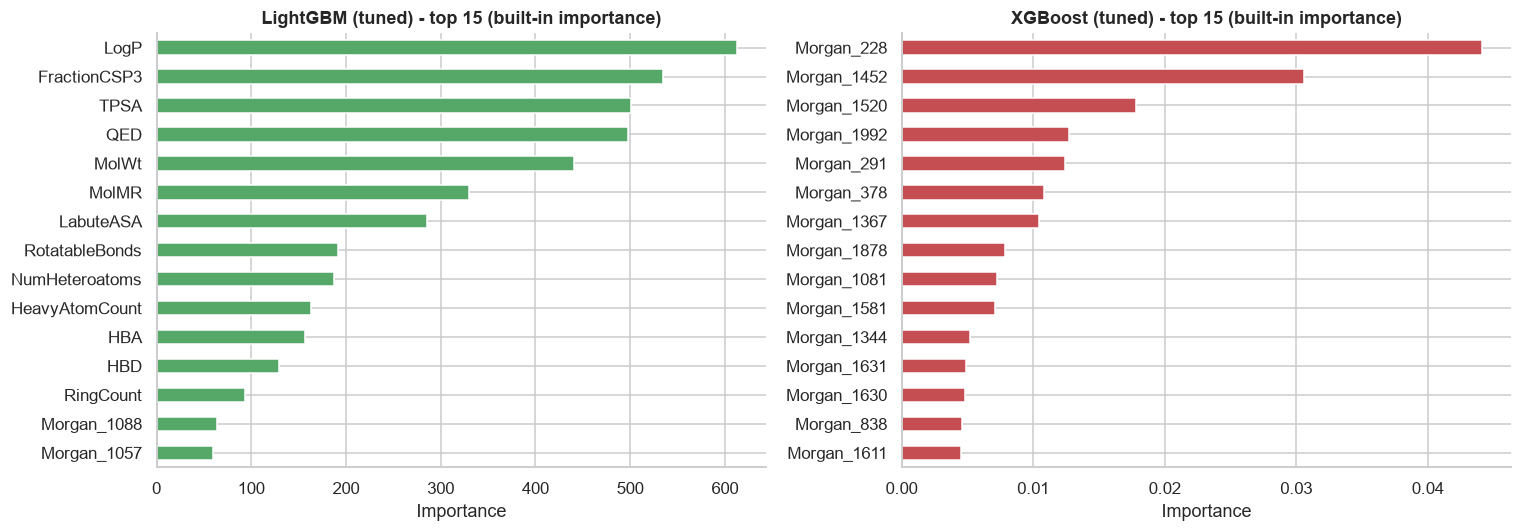

SHAP matrix: (500, 2063)


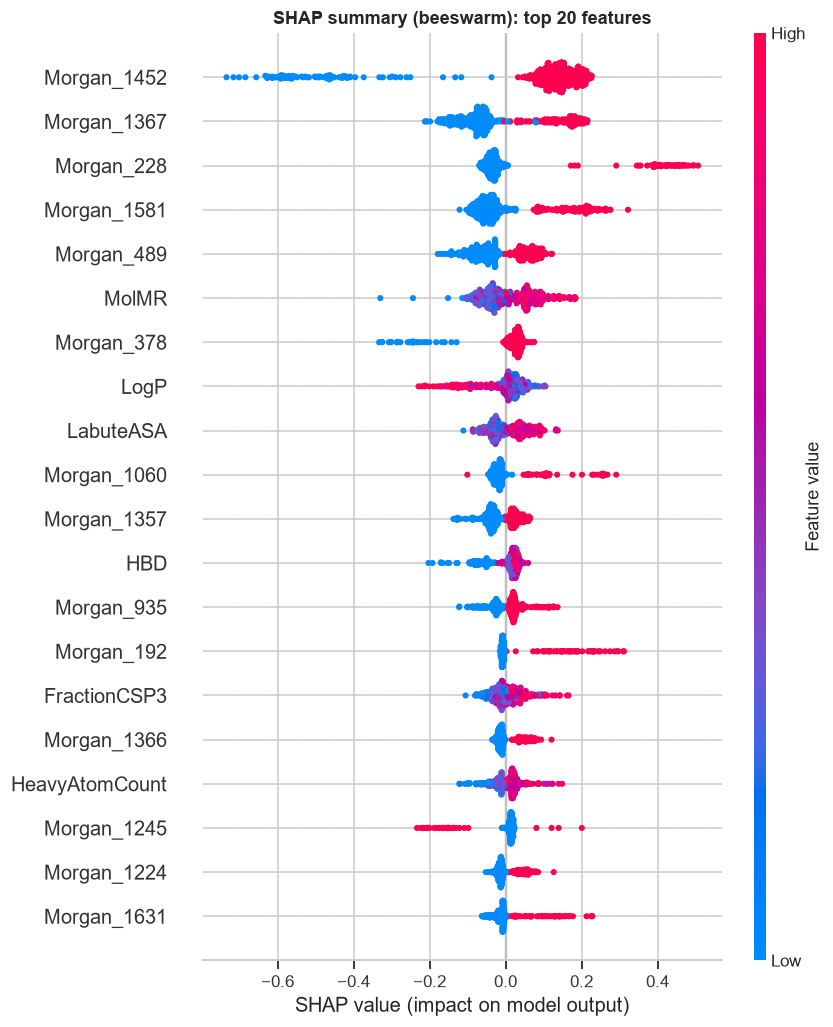

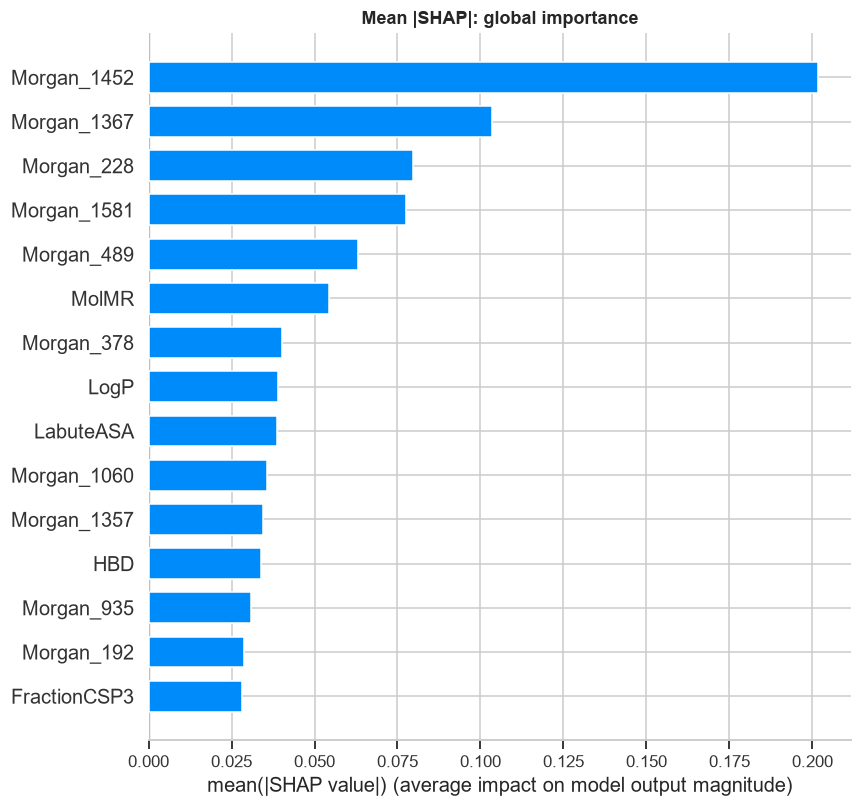

In [27]:
import shap
shap_name = final_name if "Random Forest" not in final_name else "XGBoost (tuned)"
shap_model = models[shap_name]
print("Explaining:", shap_name)

# Global gain importance for both tuned boosted models
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, nm, col in zip(axes, ["LightGBM (tuned)", "XGBoost (tuned)"], [PALETTE[2], PALETTE[3]]):
    imps = pd.Series(models[nm].feature_importances_, index=FEATURE_NAMES).sort_values(ascending=False).head(15).iloc[::-1]
    imps.plot.barh(ax=ax, color=col); ax.set_title(f"{nm} - top 15 (built-in importance)"); ax.set_xlabel("Importance")
plt.tight_layout(); plt.show()

rng = np.random.RandomState(RANDOM_STATE)
shap_idx = rng.choice(len(X_test), min(SHAP_MAX_SAMPLES, len(X_test)), replace=False)
explainer = shap.TreeExplainer(shap_model)
shap_values = explainer.shap_values(X_test[shap_idx])
print("SHAP matrix:", shap_values.shape)

plt.figure(); shap.summary_plot(shap_values, X_test[shap_idx], feature_names=FEATURE_NAMES, max_display=20, show=False)
plt.title("SHAP summary (beeswarm): top 20 features"); plt.tight_layout(); plt.show()
plt.figure(); shap.summary_plot(shap_values, X_test[shap_idx], feature_names=FEATURE_NAMES, max_display=15, plot_type="bar", show=False)
plt.title("Mean |SHAP|: global importance"); plt.tight_layout(); plt.show()

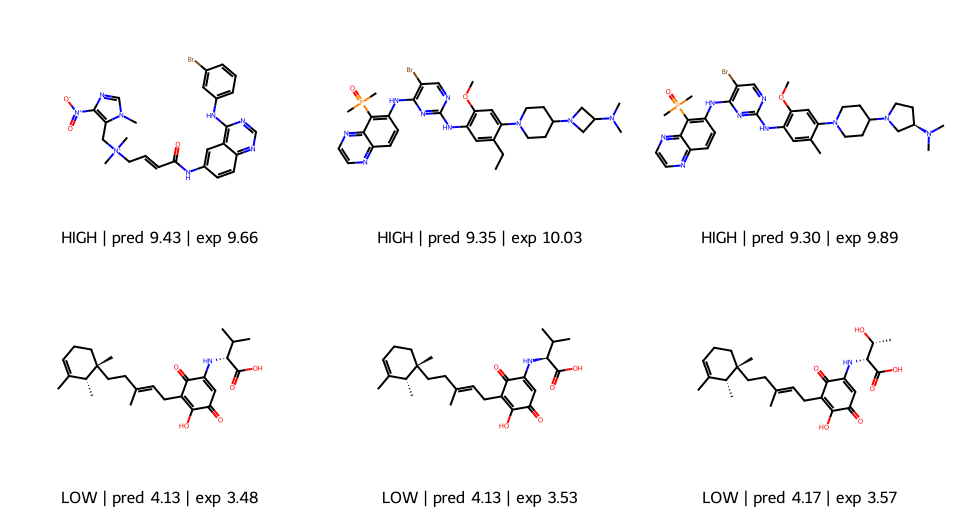

[HIGH] baseline 6.86 -> pred 9.43 | top contributors: FormalCharge=1 (+1.36), Morgan_1452=1 (+0.17), Morgan_1885=1 (+0.13), Morgan_1367=1 (+0.13), Morgan_1631=1 (+0.12)
[HIGH] baseline 6.86 -> pred 9.35 | top contributors: Morgan_192=1 (+0.30), Morgan_1631=1 (+0.23), MolMR=192 (+0.18), Morgan_1452=1 (+0.15), Morgan_1435=1 (+0.12)
[HIGH] baseline 6.86 -> pred 9.30 | top contributors: Morgan_192=1 (+0.30), Morgan_1631=1 (+0.23), MolMR=192 (+0.18), Morgan_1452=1 (+0.15), QED=0.205 (+0.13)
[LOW ] baseline 6.86 -> pred 4.13 | top contributors: Morgan_1452=0 (-0.58), Morgan_378=0 (-0.33), AromaticRings=0 (-0.20), Morgan_1215=1 (-0.19), Morgan_1389=1 (-0.13)
[LOW ] baseline 6.86 -> pred 4.13 | top contributors: Morgan_1452=0 (-0.58), Morgan_378=0 (-0.33), AromaticRings=0 (-0.20), Morgan_1215=1 (-0.19), Morgan_1389=1 (-0.13)
[LOW ] baseline 6.86 -> pred 4.17 | top contributors: Morgan_1452=0 (-0.56), Morgan_378=0 (-0.38), Morgan_1215=1 (-0.18), AromaticRings=0 (-0.18), Morgan_1389=1 (-0.13)

C

In [28]:
# Example test molecules with the highest / lowest PREDICTED activity (experimental values shown for comparison)
order_pred = np.argsort(final_pred)
ex_idx = list(order_pred[-3:][::-1]) + list(order_pred[:3])
ex_mols = [mols[test_idx[i]] for i in ex_idx]
legends = [f"{'HIGH' if k < 3 else 'LOW'} | pred {final_pred[i]:.2f} | exp {y_test[i]:.2f}" for k, i in enumerate(ex_idx)]
display(Draw.MolsToGridImage(ex_mols, molsPerRow=3, subImgSize=(320, 260), legends=legends))

ex_sv = explainer.shap_values(X_test[ex_idx])
base_val = float(np.ravel(explainer.expected_value)[0])
for k, i in enumerate(ex_idx):
    top = np.argsort(-np.abs(ex_sv[k]))[:5]
    items = ", ".join(f"{FEATURE_NAMES[j]}={X_test[i, j]:.3g} ({ex_sv[k, j]:+.2f})" for j in top)
    print(f"[{'HIGH' if k < 3 else 'LOW '}] baseline {base_val:.2f} -> pred {final_pred[i]:.2f} | top contributors: {items}")
print("\nContributions are in pIC50 units relative to the baseline (mean) prediction. They are model attributions, not mechanistic explanations.")

# 17. Applicability Domain
A QSAR model is only reliable for molecules that resemble its training data. We assess this with **Tanimoto similarity** of Morgan fingerprints: for each test molecule we compute the maximum similarity and the mean of the 5 nearest training neighbours. Predictions for molecules with low similarity are extrapolations, and the model's error is expected to be larger - we check this empirically. The `AD_THRESHOLD` (max Tanimoto ≥ 0.40) is a common heuristic, not a universal rule.

Test molecules inside AD (max Tanimoto >= 0.4): 1,978 / 2,061 (96.0%)


,R2,RMSE,MAE
inside AD,0.625,0.791,0.593
outside AD,0.136,1.209,1.036


,n,median_abs_error,mean_abs_error
sim_bin,,,
"[0.0, 0.3)",29,1.209,1.114
"[0.3, 0.4)",54,0.886,0.994
"[0.4, 0.5)",80,0.718,0.816
"[0.5, 0.6)",173,0.684,0.817
"[0.6, 0.7)",433,0.618,0.722
"[0.7, 1.01)",1292,0.373,0.506


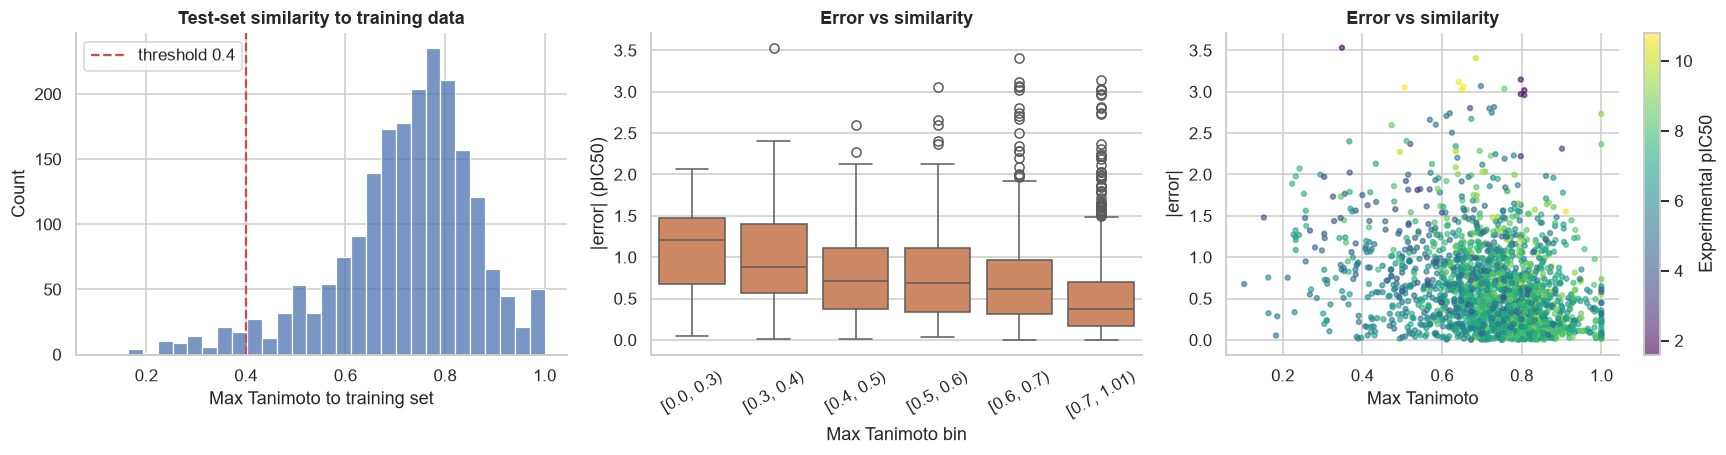

In [29]:
max_sim, knn_sim = max_sim_to_reference(fps_test, fps_train, k=5)
abs_err = np.abs(y_test - final_pred)
ad_df = pd.DataFrame({"max_sim": max_sim, "knn5_sim": knn_sim, "abs_error": abs_err})
in_ad = ad_df.max_sim >= AD_THRESHOLD
print(f"Test molecules inside AD (max Tanimoto >= {AD_THRESHOLD}): {in_ad.sum():,} / {len(ad_df):,} ({100*in_ad.mean():.1f}%)")
display(pd.DataFrame({"inside AD": regression_metrics(y_test[in_ad], final_pred[in_ad]) if in_ad.sum() > 10 else {},
                      "outside AD": regression_metrics(y_test[~in_ad], final_pred[~in_ad]) if (~in_ad).sum() > 10 else {}}).T.round(3))

bins = [0, 0.3, 0.4, 0.5, 0.6, 0.7, 1.01]
ad_df["sim_bin"] = pd.cut(ad_df.max_sim, bins, right=False)
display(ad_df.groupby("sim_bin", observed=True).abs_error.agg(n="size", median_abs_error="median", mean_abs_error="mean").round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
sns.histplot(max_sim, bins=30, ax=axes[0], color=PALETTE[0]); axes[0].axvline(AD_THRESHOLD, color="r", ls="--", label=f"threshold {AD_THRESHOLD}")
axes[0].set_xlabel("Max Tanimoto to training set"); axes[0].set_title("Test-set similarity to training data"); axes[0].legend()
sns.boxplot(data=ad_df, x="sim_bin", y="abs_error", ax=axes[1], color=PALETTE[1]); axes[1].set_xlabel("Max Tanimoto bin"); axes[1].set_ylabel("|error| (pIC50)")
axes[1].set_title("Error vs similarity"); axes[1].tick_params(axis="x", rotation=30)
sc = axes[2].scatter(max_sim, abs_err, c=y_test, cmap="viridis", s=10, alpha=0.6); plt.colorbar(sc, ax=axes[2], label="Experimental pIC50")
axes[2].set_xlabel("Max Tanimoto"); axes[2].set_ylabel("|error|"); axes[2].set_title("Error vs similarity")
plt.tight_layout(); plt.show()

# 18. Candidate Screening
Provide SMILES strings in `CANDIDATE_SMILES`. The pipeline validates and standardises each structure, computes descriptors and a Morgan fingerprint, predicts pIC50, converts it to an estimated IC50, and reports similarity to the training set.

Gefitinib and erlotinib are included as **EGFR-inhibitor workflow examples** relevant to EGFR-driven NSCLC; caffeine and an invalid string are controls. Predictions are model estimates from this dataset, not patient-response predictions or treatment recommendations.

> Predictions are not experimental results or evidence of clinical benefit. Interpret them only as estimated activity against the model's measured target, and consider the assay, mutation/construct, and applicability-domain flag.

In [30]:
CANDIDATE_SMILES = {
    "Gefitinib (EGFR inhibitor; NSCLC workflow example)": "COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1",
    "Erlotinib (EGFR inhibitor; NSCLC workflow example)": "COCCOc1cc2ncnc(Nc3cccc(C#C)c3)c2cc1OCCOC",
    "Caffeine (unrelated workflow control)": "Cn1cnc2c1c(=O)n(C)c(=O)n2C",
    "Invalid entry (validation demo)": "this_is_not_a_smiles",
}
measured_lookup = model_df.set_index("Canonical_SMILES")["pIC50"].to_dict()

def screen_candidates(smiles_dict, model, ad_threshold=AD_THRESHOLD):
    """Validate -> standardise -> descriptors + Morgan -> predict pIC50 -> IC50 (nM) -> similarity to training set."""
    records, feats, valid_pos = [], [], []
    for i, (name, smi) in enumerate(smiles_dict.items()):
        can = standardize_smiles(smi)
        if can is None:
            records.append({"Name": name, "Input SMILES": smi, "Status": "INVALID SMILES - skipped"}); continue
        mol = Chem.MolFromSmiles(can)
        d = pd.DataFrame([compute_descriptors(mol)])[DESC_COLS].replace([np.inf, -np.inf], np.nan)
        d_imp = imputer.transform(d)                                     # training-set medians
        fp = fp_bitvect(mol)
        feats.append(np.hstack([d_imp[0], fp_to_numpy(fp)]).astype(np.float32))
        records.append({"Name": name, "Input SMILES": smi, "Canonical SMILES": can, "_fp": fp}); valid_pos.append(len(records) - 1)
    if feats:
        preds = model.predict(np.vstack(feats))
        mx, _ = max_sim_to_reference([records[p]["_fp"] for p in valid_pos], fps_train)
        for p, pr, s in zip(valid_pos, preds, mx):
            records[p].update({"Predicted pIC50": pr, "Predicted IC50 (nM)": 10 ** (9 - pr), "Similarity to training set (max Tanimoto)": s,
                               "Inside applicability domain": "yes" if s >= ad_threshold else "NO - treat with caution",
                               "Measured pIC50 in dataset": measured_lookup.get(records[p]["Canonical SMILES"], np.nan), "Status": "ok"})
    out = pd.DataFrame(records).drop(columns=["_fp"], errors="ignore")
    return out

candidates_df = screen_candidates(CANDIDATE_SMILES, final_model)
show_cols = ["Name", "Predicted pIC50", "Predicted IC50 (nM)", "Similarity to training set (max Tanimoto)", "Inside applicability domain", "Measured pIC50 in dataset", "Status"]
display(candidates_df[[c for c in show_cols if c in candidates_df.columns]].style.format(
    {"Predicted pIC50": "{:.2f}", "Predicted IC50 (nM)": "{:.1f}", "Similarity to training set (max Tanimoto)": "{:.2f}", "Measured pIC50 in dataset": "{:.2f}"}, na_rep="-"))
print("Model:", final_name, "| trained on", len(train_idx), "molecules; target:", SELECTED_TARGET or "multiple targets")

,Name,Predicted pIC50,Predicted IC50 (nM),Similarity to training set (max Tanimoto),Inside applicability domain,Measured pIC50 in dataset,Status
0,Gefitinib (EGFR inhibitor; NSCLC workflow example),7.62,23.9,1.00,yes,7.66,ok
1,Erlotinib (EGFR inhibitor; NSCLC workflow example),7.71,19.4,1.00,yes,7.52,ok
2,Caffeine (unrelated workflow control),5.24,5715.2,0.26,NO - treat with caution,-,ok
3,Invalid entry (validation demo),-,-,-,-,-,INVALID SMILES - skipped


Model: Random Forest (tuned) | trained on 8246 molecules; target: Epidermal growth factor receptor


In [31]:
# Replace or add entries with the candidate molecules you want to score.
PREDICTION_CANDIDATES = {
    "Gefitinib (EGFR workflow example)": "COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1",
}

prediction_results = screen_candidates(PREDICTION_CANDIDATES, final_model)
display(prediction_results)
print("Selected model:", final_name)
print("Measured target:", SELECTED_TARGET or "multiple targets")

,Name,Input SMILES,Canonical SMILES,Predicted pIC50,Predicted IC50 (nM),Similarity to training set (max Tanimoto),Inside applicability domain,Measured pIC50 in dataset,Status
0,Gefitinib (EGFR workflow example),COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1,7.621143,23.92529,1.0,yes,7.657577,ok


Selected model: Random Forest (tuned)
Measured target: Epidermal growth factor receptor


# 21. Relevance to Lung Cancer Research

**Lung cancer and molecular targets.** Lung cancer is a group of diseases. EGFR mutations and other driver alterations occur in subsets of NSCLC; treatment depends on tumor molecular testing and clinical guidance. This notebook screens for EGFR and other lung-cancer-associated target names, but a name match alone is not a diagnosis, treatment indication, or proof of clinical relevance.

**What this dataset measures.** The supplied BindingDB-style file is dominated by **EGFR** measurements, including wild-type protein and multiple constructs or mutations. This supports an EGFR biochemical activity modeling exercise that is relevant to a subset of lung-cancer research. The resulting QSAR model estimates activity against the recorded EGFR construct and assay; it does **not** predict tumor response, patient benefit, or survival.

**Why target and mutation identity matter.** IC50 depends on the protein construct, mutation, assay, and experimental conditions. Activity measured against one EGFR construct may not transfer to other mutations, other lung-cancer drivers, or a patient's tumor. The notebook's `TARGET_FILTER="top"` uses the most frequent exact target name; inspect the target distribution and mutation annotations before interpreting that selected target.

For stronger lung-cancer conclusions, use assay-verified data for a specific driver and mutation, keep endpoint types and assay conditions consistent, and validate predictions experimentally. Cell-based tumor response, selectivity, toxicity, pharmacokinetics, and clinical evidence are outside this notebook's scope.

In [32]:
# Data-derived statement (updates automatically if a different dataset is loaded)
lung_cancer_target_in_model_set = not lung_cancer_hits_clean.empty
msg = (f"- Target(s) used for modelling: **{SELECTED_TARGET or 'all targets in file'}** ({work['Target Name'].nunique()} distinct target name(s) in cleaned records)\n"
       f"- Most frequent base target in the raw file: **{top_base}** ({top_share:.1f}% of {len(df):,} records)\n"
       f"- Lung-cancer-associated target screen: **{'MATCHES FOUND - review target/assay context: ' + ', '.join(lung_cancer_hits_clean['matched name'].unique()[:5]) if lung_cancer_target_in_model_set else 'no screened matches'}**\n"
       f"- Interpretation: **{'target-name match supports relevance for review, but does not imply tumor response or clinical efficacy' if lung_cancer_target_in_model_set else 'no lung-cancer-associated targets were identified by this screen'}**")
display(Markdown(msg))

- Target(s) used for modelling: **Epidermal growth factor receptor** (1 distinct target name(s) in cleaned records)
- Most frequent base target in the raw file: **Epidermal growth factor receptor** (99.1% of 27,399 records)
- Lung-cancer-associated target screen: **MATCHES FOUND - review target/assay context: Epidermal growth factor receptor**
- Interpretation: **target-name match supports relevance for review, but does not imply tumor response or clinical efficacy**

# 22. Results Summary
Generated automatically from the objects computed above.

In [33]:
summary = {
    "Original records in file":                          f"{n_original:,}",
    "Records with valid RDKit structures (after IC50 filtering)": f"{n_valid_structures:,}",
    "Records after cleaning":                            f"{len(work):,}",
    "Unique compounds (canonical SMILES) used for modelling": f"{len(model_df):,}",
    "Modelling target":                                  SELECTED_TARGET or "all targets in file",
    "IC50 range (nM, record level)":                     f"{work['IC50 (nM)'].min():.3g} - {work['IC50 (nM)'].max():.3g}",
    "pIC50 range (compound level, median)":              f"{model_df.pIC50.min():.2f} - {model_df.pIC50.max():.2f} (mean {model_df.pIC50.mean():.2f})",
    "RDKit descriptors":                                 len(DESC_COLS),
    "Morgan fingerprint":                                f"{N_BITS} bits, radius {MORGAN_RADIUS}",
    "Total features (combined)":                         X_comb.shape[1],
    "Split":                                             "Bemis-Murcko scaffold (balanced)",
    "Train / test sizes":                                f"{len(train_idx):,} / {len(test_idx):,}",
    "Selected model (lowest CV RMSE)":                   final_name,
    "Test-set fraction inside applicability domain":     f"{100*in_ad.mean():.1f}%",
}
display(pd.Series(summary, name="value").to_frame())
display(Markdown("**Test-set performance (scaffold split)**"))
display(full_cmp.loc[[m for m in order if m in full_cmp.index]].round(3))
display(Markdown("**5-fold scaffold-grouped cross-validation (training set, untuned models)**"))
display(cv_df.round(3))

,value
Original records in file,"27,399"
Records with valid RDKit structures (after IC50 filtering),"15,379"
Records after cleaning,"15,379"
Unique compounds (canonical SMILES) used for modelling,"10,307"
Modelling target,Epidermal growth factor receptor
"IC50 range (nM, record level)",0.002 - 8.3e+07
"pIC50 range (compound level, median)",1.60 - 11.52 (mean 6.87)
RDKit descriptors,15
Morgan fingerprint,"2048 bits, radius 2"
Total features (combined),2063


**Test-set performance (scaffold split)**

,R²,RMSE,MAE,Train time (s)
Model,,,,
Random Forest,0.626,0.801,0.601,51.4
LightGBM,0.616,0.812,0.609,3.9
XGBoost,0.613,0.815,0.617,12.8
Random Forest (tuned),0.616,0.812,0.611,67.8
LightGBM (tuned),0.613,0.816,0.609,2.4
XGBoost (tuned),0.618,0.810,0.608,11.3


**5-fold scaffold-grouped cross-validation (training set, untuned models)**

,R² mean,R² SD,RMSE mean,RMSE SD,MAE mean,MAE SD
Model,,,,,,
Random Forest,0.604,0.045,0.860,0.032,0.651,0.018
LightGBM,0.584,0.042,0.882,0.026,0.670,0.018
XGBoost,0.581,0.043,0.885,0.028,0.676,0.019


# 23. Limitations
**Data and experiment**
* **Assay variability** - IC50 depends on assay conditions, substrate, buffer, temperature, and laboratory. Inter-measurement spread (Section 6) limits attainable accuracy.
* **IC50 vs Ki** - IC50 is assay-dependent, whereas Ki is a thermodynamic constant (related via the Cheng-Prusoff equation). They should not be pooled without care; only IC50 is modelled here.
* **Dataset bias** - literature-derived sets over-represent successful chemical series and published (mostly potent) compounds; inactive compounds and censored values (`<`, `>`) were removed, biasing the activity range.
* **Duplicate measurements** - reduced by median aggregation, but the median of heterogeneous assays still blends different conditions; mutant and wild-type constructs may be pooled if `TARGET_FILTER=None`.
* **Chemical-space bias** - kinase-inhibitor-like scaffolds dominate; models will not generalise to unrelated chemotypes.

**Modelling**
* **Scaffold leakage** - a scaffold split reduces but cannot eliminate near-analogue leakage (similar compounds can have different scaffolds). Always read results together with the applicability-domain analysis.
* **Applicability domain** - the similarity-threshold method is heuristic; low-similarity predictions are extrapolations.
* **Activity cliffs** - small structural changes can cause large potency changes that fingerprint-based models handle poorly.
* **Single split / limited tuning** - one test split and a lightweight random search; differences between models may not be statistically meaningful.
* **Target specificity** - this dataset is EGFR-dominated. Predictions concern measured EGFR-associated bioactivity and do not directly predict response of a lung tumor or patient.
* **Mutation and assay context** - constructs, mutations, and assay conditions can affect potency; results should not be generalized across EGFR variants or other lung-cancer drivers without validation.
* **Limited biological context** - no cell-based tumor response, selectivity, toxicity, pharmacokinetics, or clinical outcomes are modelled.

**Additional considerations for lung-cancer research.** Confirm the molecular driver and mutation, use assay-matched target data, and validate predictions in relevant cell models. Clinical treatment decisions require validated diagnostics and medical evidence; this QSAR workflow does not provide treatment recommendations.

Descriptor values such as TPSA or logP are model inputs, not validated predictions of drug suitability, safety, or clinical benefit.

# 24. Export Results
Saved to `outputs/`: cleaned dataset, descriptors, model comparison (test + CV), candidate predictions, and trained models (`joblib`) together with the preprocessing objects needed to reproduce predictions. Random-forest files can be large (hundreds of MB); compression is applied.

In [34]:
# Cleaned dataset (with split label) and raw descriptors
export_df = model_df.copy(); export_df["Split"] = "train"; export_df.loc[test_idx, "Split"] = "test"
export_df.to_csv(f"{OUTPUT_DIR}/cleaned_dataset.csv", index=False)
pd.concat([model_df[["Canonical_SMILES"]], desc_raw], axis=1).to_csv(f"{OUTPUT_DIR}/molecular_descriptors.csv", index=False)

# Model comparison: test metrics + cross-validation metrics
cmp_out = full_cmp.loc[[m for m in order if m in full_cmp.index]].join(cv_df, how="left")
cmp_out.round(4).to_csv(f"{OUTPUT_DIR}/model_comparison.csv")
candidates_df.to_csv(f"{OUTPUT_DIR}/predicted_candidates.csv", index=False)

# Models + preprocessing bundle
joblib.dump(models["Random Forest"], f"{OUTPUT_DIR}/random_forest_pIC50.joblib", compress=3)
joblib.dump(models["LightGBM"],      f"{OUTPUT_DIR}/lightgbm_pIC50.joblib", compress=3)
joblib.dump(models["XGBoost"],       f"{OUTPUT_DIR}/xgboost_pIC50.joblib", compress=3)
joblib.dump(final_model,             f"{OUTPUT_DIR}/selected_model_pIC50.joblib", compress=3)
joblib.dump({"imputer": imputer, "scaler": scaler, "descriptor_columns": DESC_COLS, "morgan_radius": MORGAN_RADIUS,
             "n_bits": N_BITS, "feature_names": FEATURE_NAMES, "selected_model": final_name,
             "target": SELECTED_TARGET, "endpoint": "pIC50 = 9 - log10(IC50 nM)", "random_state": RANDOM_STATE},
            f"{OUTPUT_DIR}/preprocessing_and_metadata.joblib")

for f in sorted(os.listdir(OUTPUT_DIR)):
    print(f"{f:<42s} {os.path.getsize(os.path.join(OUTPUT_DIR, f))/1e6:8.2f} MB")
# Colab download:  from google.colab import files; [files.download(f"{OUTPUT_DIR}/{f}") for f in os.listdir(OUTPUT_DIR)]

cleaned_dataset.csv                            1.91 MB
lightgbm_pIC50.joblib                          0.51 MB
model_comparison.csv                           0.00 MB
molecular_descriptors.csv                      2.19 MB
predicted_candidates.csv                       0.00 MB
preprocessing_and_metadata.joblib              0.03 MB
random_forest_pIC50.joblib                    85.42 MB
selected_model_pIC50.joblib                   42.85 MB
xgboost_pIC50.joblib                           0.48 MB


# 25. Final Project Conclusion

**What was modelled.** The workflow models pIC50 derived from IC50 (nM) against the target(s) in the supplied BindingDB-style file. The configured data are EGFR-dominated, including multiple EGFR constructs and mutations, making this an EGFR bioactivity QSAR workflow relevant to a subset of lung-cancer research.

**How molecules were represented.** Standardised canonical SMILES were converted into (i) interpretable RDKit physicochemical descriptors and (ii) 2048-bit Morgan (radius-2) fingerprints, alone and combined.

**Algorithms tested.** Random Forest, LightGBM and XGBoost (baseline and randomized-search-tuned), with optional GNN and ChemBERTa extensions.

**How performance was evaluated.** One row per compound (median aggregation), a Bemis-Murcko scaffold split with no scaffold/molecule overlap, preprocessing fitted on training data only, scaffold-grouped 5-fold CV for model selection, R²/RMSE/MAE with bootstrap intervals, a random-split comparison to expose leakage, and Tanimoto-based applicability-domain analysis.

**What the predictions mean.** Estimates of in-vitro potency against the measured target/construct and assay context, for molecules similar to the training chemistry, with error summarized by the reported model metrics.

**What they do not mean.** They are not experimental measurements and do not establish tumor response, patient benefit, survival, clinical efficacy, mutation-independent activity, pharmacokinetics, selectivity, or toxicity.

**Lung-cancer interpretation.** EGFR is a relevant target in subsets of NSCLC, but this dataset and model do not represent lung cancer as a whole and are not clinical-response predictors. Stronger disease-specific conclusions require mutation- and assay-verified data plus biological validation.